# DS203 Regression Project – Inflation Forecasting
## Introduction
## Data Setup, Feature Engineering, EDA, Model Training and Evaluation

**Goal:** Use macroeconomic information available in month *t* to predict U.S. year-over-year CPI inflation *n* months ahead, where *n* ∈ {1, 3, 6, 12}. This notebook covers the complete workflow, including data setup, feature engineering, exploratory data analysis (EDA), preprocessing, outlier treatment, model training, hyperparameter tuning, feature selection, and model evaluation.

Run this notebook with the 11 FRED CSV files placed in the same folder as the notebook.

## 1. Setup

In [193]:
%pip install seaborn

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

DATA_DIR = "."
TARGET_SERIES = "CPIAUCSL"
PREDICTOR_SERIES = ["T10Y2Y", "UNRATE", "INDPRO", "FEDFUNDS", "PAYEMS",
                    "PPIACO", "HOUST", "DCOILWTICO", "M2SL", "UMCSENT"]
ALL_SERIES = [TARGET_SERIES] + PREDICTOR_SERIES
DAILY_SERIES = ["T10Y2Y", "DCOILWTICO"]

SERIES_INFO = {
    "CPIAUCSL":   ("Consumer Price Index", "Index 1982-84=100"),
    "T10Y2Y":     ("10-year minus 2-year Treasury yield spread", "Percentage points"),
    "UNRATE":     ("Unemployment rate", "Percent"),
    "INDPRO":     ("Industrial Production Index", "Index 2017=100"),
    "FEDFUNDS":   ("Federal funds rate", "Percent"),
    "PAYEMS":     ("Nonfarm payroll employment", "Thousands of persons"),
    "PPIACO":     ("Producer Price Index", "Index 1982=100"),
    "HOUST":      ("Housing starts", "Thousands of units"),
    "DCOILWTICO": ("WTI crude oil price", "Dollars per barrel"),
    "M2SL":       ("M2 money supply", "Billions of dollars"),
    "UMCSENT":    ("Consumer sentiment", "Index 1966:Q1=100"),
}

HORIZONS = [1, 3, 6, 12]
TARGET_COLS = [f"target_{n}m" for n in HORIZONS]

REGIME_BINS = [-np.inf, 0.0, 2.0, 4.0, np.inf]
REGIME_LABELS = ["Deflation (< 0%)", "Low (0–2%)", "Moderate (2–4%)", "High (≥ 4%)"]
RAPID_WINDOW = 6
RAPID_CHANGE_PP = 2.0

SAVE_FIGURES = False
FIG_DIR = "figures"
if SAVE_FIGURES:
    os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

In [194]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
REGIME_COLORS = {"Deflation (< 0%)": "#2a78d6", "Low (0–2%)": "#1baf7a", "High (≥ 4%)": "#e34948"}
CORR_CMAP = "RdBu_r"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.frameon": False, "legend.fontsize": 9.5, "lines.linewidth": 1.8,
})


def format_year_axis(ax, step=4):
    if "START" in globals():
        ax.set_xlim(START - pd.DateOffset(months=6), END + pd.DateOffset(months=6))
    ax.xaxis.set_major_locator(mdates.YearLocator(step))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, name + ".png"))
    plt.show()


def ym(ts):
    return pd.Timestamp(ts).strftime("%b %Y")

## 2. Loading the data

Each CSV has an `observation_date` column and a value column named after its FRED ID. Dates are parsed
and empty cells become `NaN`.

In [195]:
raw = {}
audit_rows = []
for sid in ALL_SERIES:
    df = pd.read_csv(os.path.join(DATA_DIR, sid + ".csv"))
    df["observation_date"] = pd.to_datetime(df["observation_date"])
    s = pd.to_numeric(df[sid], errors="coerce")
    s.index = df["observation_date"]
    s.name = sid
    raw[sid] = s

    median_gap = s.index.to_series().diff().dt.days.median()
    audit_rows.append({
        "Series": sid,
        "Description": SERIES_INFO[sid][0],
        "Units": SERIES_INFO[sid][1],
        "Frequency": "Daily" if median_gap < 7 else "Monthly",
        "First date": s.index.min().date(),
        "Last date": s.index.max().date(),
        "Rows": len(s),
        "Missing values": int(s.isna().sum()),
    })

raw_audit = pd.DataFrame(audit_rows).set_index("Series")
display(raw_audit)

,Description,Units,Frequency,First date,Last date,Rows,Missing values
Series,,,,,,,
CPIAUCSL,Consumer Price Index,Index 1982-84=100,Monthly,1947-01-01,2026-10-01,958,1
T10Y2Y,10-year minus 2-year Treasury yield spread,Percentage points,Daily,1976-06-01,2026-11-18,13167,554
UNRATE,Unemployment rate,Percent,Monthly,1948-01-01,2026-10-01,946,1
INDPRO,Industrial Production Index,Index 2017=100,Monthly,1919-01-01,2026-10-01,1294,0
FEDFUNDS,Federal funds rate,Percent,Monthly,1954-07-01,2026-10-01,868,0
PAYEMS,Nonfarm payroll employment,Thousands of persons,Monthly,1939-01-01,2026-10-01,1054,0
PPIACO,Producer Price Index,Index 1982=100,Monthly,1913-01-01,2026-10-01,1366,0
HOUST,Housing starts,Thousands of units,Monthly,1959-01-01,2026-10-01,814,0
DCOILWTICO,WTI crude oil price,Dollars per barrel,Daily,1986-01-02,2026-11-17,10664,1117


* `T10Y2Y` and `DCOILWTICO` are daily; their missing values are non-trading days.
* `UMCSENT` was quarterly before 1978, which gives its early missing months.
* `CPIAUCSL` and `UNRATE` have no value for October 2025. This is left as `NaN`.

## 3. Common monthly panel

* Daily series are converted to monthly by taking the mean of all trading days in the month.
* All series are indexed at the first day of the month.
* The analysis window runs from the latest start date to the earliest end date across all 11 series.

In [196]:
monthly = {}
for sid, s in raw.items():
    if sid in DAILY_SERIES:
        monthly[sid] = s.resample("MS").mean()
    else:
        monthly[sid] = s.resample("MS").first()

panel_full = pd.concat(monthly, axis=1, sort=True)[ALL_SERIES]

first_valid = {sid: panel_full[sid].first_valid_index() for sid in ALL_SERIES}
last_valid = {sid: panel_full[sid].last_valid_index() for sid in ALL_SERIES}
START = max(first_valid.values())
END = min(last_valid.values())

print("Latest start  :", ym(START), [k for k, v in first_valid.items() if v == START])
print("Earliest end  :", ym(END), [k for k, v in last_valid.items() if v == END])
print("Window        :", ym(START), "to", ym(END))
print("Observations  :", len(panel_full.loc[START:END]))

Latest start  : Jan 1986 ['DCOILWTICO']
Earliest end  : Sep 2026 ['M2SL', 'UMCSENT']
Window        : Jan 1986 to Sep 2026
Observations  : 489


## 4. Inflation and targets

$$\text{Inflation}_t = 100\left(\frac{\text{CPI}_t}{\text{CPI}_{t-12}} - 1\right)$$

Target for horizon $n$: $y^{(n)}_t = \text{Inflation}_{t+n}$, created with `inflation.shift(-n)`.

Inflation is computed on the full CPI history before restricting to the window, so the first months of
the window have a value.

In [197]:
cpi = panel_full[TARGET_SERIES]
inflation_full = 100 * (cpi / cpi.shift(12) - 1)
inflation_full.name = "inflation"

targets_full = pd.DataFrame({f"target_{n}m": inflation_full.shift(-n) for n in HORIZONS})

## 5. Feature engineering

Every feature for month *t* uses only values from month *t* or earlier.

* Monthly change: $\Delta X_t = X_t - X_{t-1}$
* Year-over-year growth: $\text{Growth}_{X,t} = 100\left(\frac{X_t}{X_{t-12}} - 1\right)$

| Feature | Source | Definition |
|---|---|---|
| `T10Y2Y`, `UNRATE`, `INDPRO`, `FEDFUNDS`, `PAYEMS`, `PPIACO`, `HOUST`, `DCOILWTICO`, `M2SL`, `UMCSENT` | FRED | Monthly level |
| `UNRATE_chg_1m` | UNRATE | Monthly change |
| `INDPRO_yoy` | INDPRO | YoY growth, % |
| `PAYEMS_yoy` | PAYEMS | YoY growth, % |
| `PPIACO_yoy` | PPIACO | YoY growth, % |
| `DCOILWTICO_yoy` | DCOILWTICO | YoY growth, % |
| `M2SL_yoy` | M2SL | YoY growth, % |
| `HOUST_yoy` | HOUST | YoY growth, % |
| `FEDFUNDS_chg_1m` | FEDFUNDS | Monthly change |
| `T10Y2Y_chg_1m` | T10Y2Y | Monthly change |
| `UMCSENT_chg_1m` | UMCSENT | Monthly change |

CPI and inflation are not used as predictors.

In [198]:
def yoy_growth(x):
    return 100 * (x / x.shift(12) - 1)


def monthly_change(x):
    return x - x.shift(1)


feat = pd.DataFrame(index=panel_full.index)
for sid in PREDICTOR_SERIES:
    feat[sid] = panel_full[sid]

feat["UNRATE_chg_1m"] = monthly_change(panel_full["UNRATE"])
for sid in ["INDPRO", "PAYEMS", "PPIACO", "DCOILWTICO", "M2SL", "HOUST"]:
    feat[f"{sid}_yoy"] = yoy_growth(panel_full[sid])
for sid in ["FEDFUNDS", "T10Y2Y", "UMCSENT"]:
    feat[f"{sid}_chg_1m"] = monthly_change(panel_full[sid])

FEATURES = list(feat.columns)

features = feat.loc[START:END].copy()
inflation = inflation_full.loc[START:END].copy()
targets = targets_full.loc[START:END].copy()

data = pd.concat([features, inflation, targets], axis=1)
data.index.name = "date"

print("Features:", len(FEATURES))
print(FEATURES)
print("Dataset shape:", data.shape)

Features: 20
['T10Y2Y', 'UNRATE', 'INDPRO', 'FEDFUNDS', 'PAYEMS', 'PPIACO', 'HOUST', 'DCOILWTICO', 'M2SL', 'UMCSENT', 'UNRATE_chg_1m', 'INDPRO_yoy', 'PAYEMS_yoy', 'PPIACO_yoy', 'DCOILWTICO_yoy', 'M2SL_yoy', 'HOUST_yoy', 'FEDFUNDS_chg_1m', 'T10Y2Y_chg_1m', 'UMCSENT_chg_1m']
Dataset shape: (489, 25)


## 6. EDA

### 6.1 Dataset inspection

In [199]:
print("Date range      :", ym(data.index.min()), "–", ym(data.index.max()))
print("Dimensions      :", data.shape[0], "rows x", data.shape[1], "columns")
print("Frequency       :", pd.infer_freq(data.index))
print("Duplicate dates :", data.index.duplicated().sum())

col_info = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "Role": ["Target" if c in TARGET_COLS else ("Inflation" if c == "inflation" else "Feature")
             for c in data.columns],
    "Non-missing": data.notna().sum(),
    "Missing (NaN)": data.isna().sum(),
})
display(col_info)

Date range      : Jan 1986 – Sep 2026
Dimensions      : 489 rows x 25 columns
Frequency       : MS
Duplicate dates : 0


,dtype,Role,Non-missing,Missing (NaN)
T10Y2Y,float64,Feature,489,0
UNRATE,float64,Feature,488,1
INDPRO,float64,Feature,489,0
FEDFUNDS,float64,Feature,489,0
PAYEMS,float64,Feature,489,0
PPIACO,float64,Feature,489,0
HOUST,float64,Feature,489,0
DCOILWTICO,float64,Feature,489,0
M2SL,float64,Feature,489,0
UMCSENT,float64,Feature,489,0


All columns are continuous numeric. Missing values come from:

* `DCOILWTICO_yoy`: first 12 months (oil data starts in Jan 1986).
* `UNRATE`, `UNRATE_chg_1m`, `inflation`, targets: the October 2025 gap.
* Targets: the last *n* months, where inflation *n* months ahead is not yet available.

In [200]:
summary = data.describe().T
summary["median"] = data.median()
summary["skew"] = data.skew()
summary["kurtosis"] = data.kurt()
summary = summary[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skew", "kurtosis"]]
display(summary.round(2))

,count,mean,median,std,min,25%,75%,max,skew,kurtosis
T10Y2Y,489.0,0.96,0.82,0.88,-0.93,0.25,1.68,2.83,0.29,-0.90
UNRATE,488.0,5.68,5.40,1.67,3.40,4.40,6.60,14.80,1.28,2.42
INDPRO,489.0,87.49,92.95,15.41,54.90,73.68,100.17,104.10,-0.83,-0.83
FEDFUNDS,489.0,3.35,3.34,2.63,0.05,0.54,5.33,9.85,0.27,-1.00
PAYEMS,489.0,131356.00,132234.00,16138.89,98732.00,118992.00,142733.00,159128.00,-0.20,-0.79
PPIACO,489.0,167.30,164.30,49.37,99.30,124.70,200.70,294.47,0.56,-0.67
HOUST,489.0,1350.83,1380.00,367.55,478.00,1146.00,1587.00,2273.00,-0.32,-0.08
DCOILWTICO,489.0,48.79,44.72,29.55,11.34,20.29,71.71,133.88,0.53,-0.90
M2SL,489.0,9121.90,6815.70,6267.98,2501.60,3685.40,12907.30,23413.90,0.92,-0.43
UMCSENT,489.0,84.69,88.80,14.14,44.80,74.30,94.70,112.00,-0.55,-0.39


### 6.2 Inflation over time

| Period | Definition |
|---|---|
| Deflation | $\text{Inflation}_t < 0\%$ |
| Low inflation | $0\% \le \text{Inflation}_t < 2\%$ |
| Moderate inflation | $2\% \le \text{Inflation}_t < 4\%$ |
| High inflation | $\text{Inflation}_t \ge 4\%$ |
| Rapid change | $\lvert \text{Inflation}_t - \text{Inflation}_{t-6} \rvert \ge 2$ percentage points |

The 2 % threshold is the Federal Reserve's inflation target.

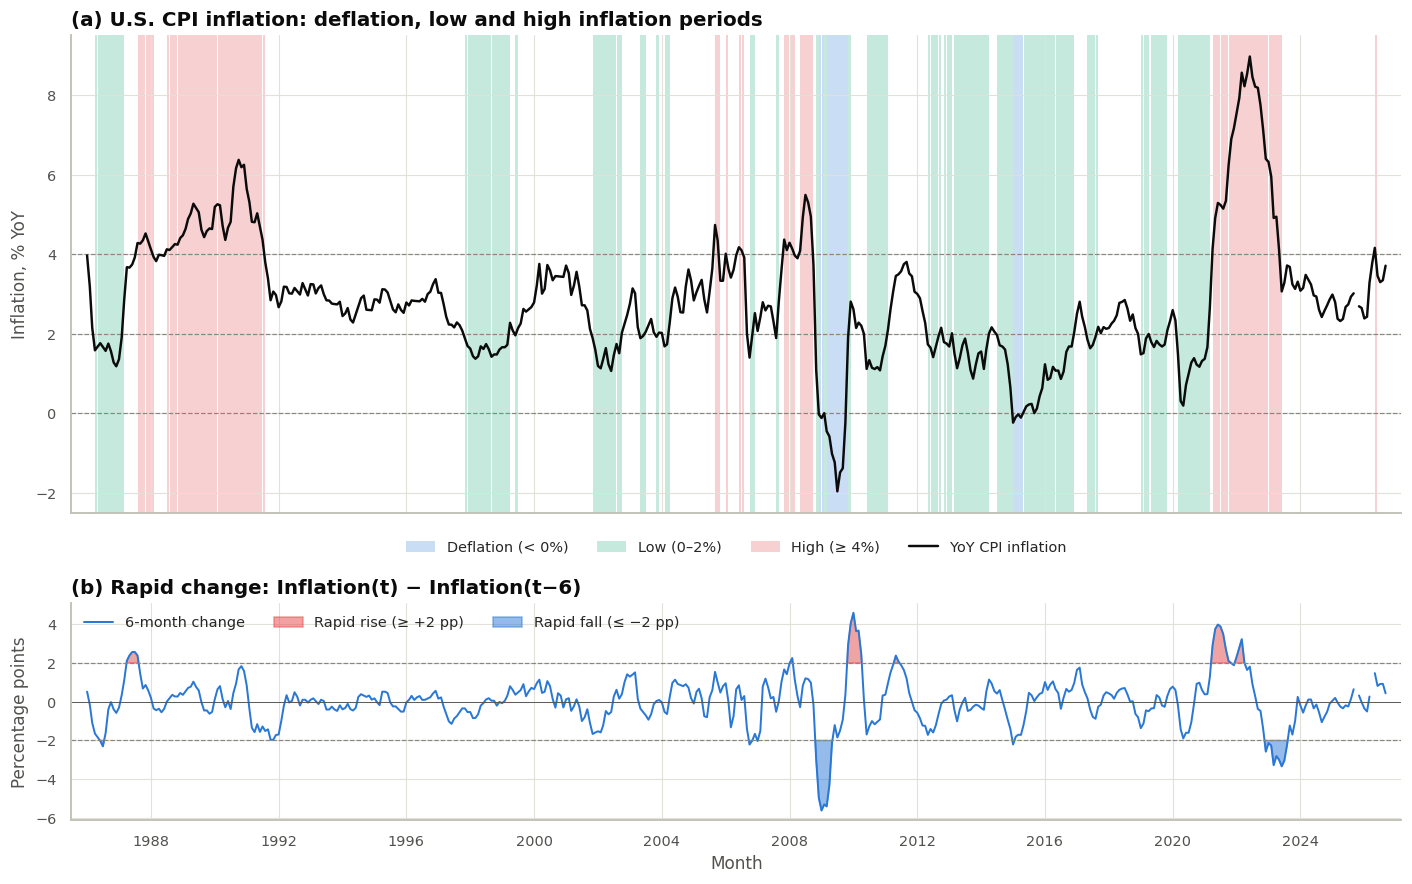

In [201]:
regime = pd.cut(inflation, bins=REGIME_BINS, labels=REGIME_LABELS, right=False)
change_6m = (inflation_full - inflation_full.shift(RAPID_WINDOW)).loc[START:END]
rapid_rise = change_6m >= RAPID_CHANGE_PP
rapid_fall = change_6m <= -RAPID_CHANGE_PP

fig, axes = plt.subplots(2, 1, figsize=(13, 8.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})

ax = axes[0]
month_end = inflation.index + pd.offsets.MonthEnd(0)
for lab, color in REGIME_COLORS.items():
    first = True
    for start, end, r in zip(inflation.index, month_end, regime):
        if r == lab:
            ax.axvspan(start, end, color=color, alpha=0.25, lw=0, zorder=0, label=lab if first else None)
            first = False
ax.plot(inflation.index, inflation, color=INK, lw=1.6, label="YoY CPI inflation", zorder=3)
for y in [0, 2, 4]:
    ax.axhline(y, color=MUTED, lw=0.8, ls="--", zorder=1)
ax.set_ylabel("Inflation, % YoY")
ax.set_title("(a) U.S. CPI inflation: deflation, low and high inflation periods")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.03))

ax = axes[1]
ax.plot(change_6m.index, change_6m, color=PALETTE[0], lw=1.3, label="6-month change")
ax.fill_between(change_6m.index, RAPID_CHANGE_PP, change_6m, where=rapid_rise, color=PALETTE[7], alpha=0.5,
                interpolate=True, label=f"Rapid rise (≥ +{RAPID_CHANGE_PP:g} pp)")
ax.fill_between(change_6m.index, -RAPID_CHANGE_PP, change_6m, where=rapid_fall, color=PALETTE[0], alpha=0.5,
                interpolate=True, label=f"Rapid fall (≤ −{RAPID_CHANGE_PP:g} pp)")
for y in [RAPID_CHANGE_PP, -RAPID_CHANGE_PP]:
    ax.axhline(y, color=MUTED, lw=0.8, ls="--")
ax.axhline(0, color=INK_2, lw=0.6)
ax.set_ylabel("Percentage points")
ax.set_xlabel("Month")
ax.set_title(f"(b) Rapid change: Inflation(t) − Inflation(t−{RAPID_WINDOW})")
ax.legend(ncol=3, loc="upper left")
format_year_axis(ax)
finish(fig, "inflation_over_time")

In [202]:
counts = regime.value_counts().reindex(REGIME_LABELS)
period_table = pd.DataFrame({"Months": counts, "% of months": (100 * counts / regime.notna().sum()).round(1)})
period_table.loc["Rapid rise"] = [rapid_rise.sum(), round(100 * rapid_rise.mean(), 1)]
period_table.loc["Rapid fall"] = [rapid_fall.sum(), round(100 * rapid_fall.mean(), 1)]
period_table.index.name = "Period"
display(period_table)

print("Highest inflation:", round(inflation.max(), 2), "% in", ym(inflation.idxmax()))
print("Lowest inflation :", round(inflation.min(), 2), "% in", ym(inflation.idxmin()))
print("Largest 6-month rise:", round(change_6m.max(), 2), "pp in", ym(change_6m.idxmax()))
print("Largest 6-month fall:", round(change_6m.min(), 2), "pp in", ym(change_6m.idxmin()))

,Months,% of months
Period,,
Deflation (< 0%),14.0,2.9
Low (0–2%),130.0,26.6
Moderate (2–4%),260.0,53.3
High (≥ 4%),84.0,17.2
Rapid rise,24.0,4.9
Rapid fall,22.0,4.5


Highest inflation: 8.98 % in Jun 2022
Lowest inflation : -1.96 % in Jul 2009
Largest 6-month rise: 4.58 pp in Jan 2010
Largest 6-month fall: -5.61 pp in Jan 2009


,Mean %,Median %,Std,Min %,Max %
Decade,,,,,
1980s,3.60,4.05,1.24,1.19,5.28
1990s,3.01,2.82,1.13,1.38,6.38
2000s,2.57,2.80,1.42,-1.96,5.50
2010s,1.77,1.74,0.86,-0.23,3.81
2020s,3.90,3.25,2.23,0.20,8.98


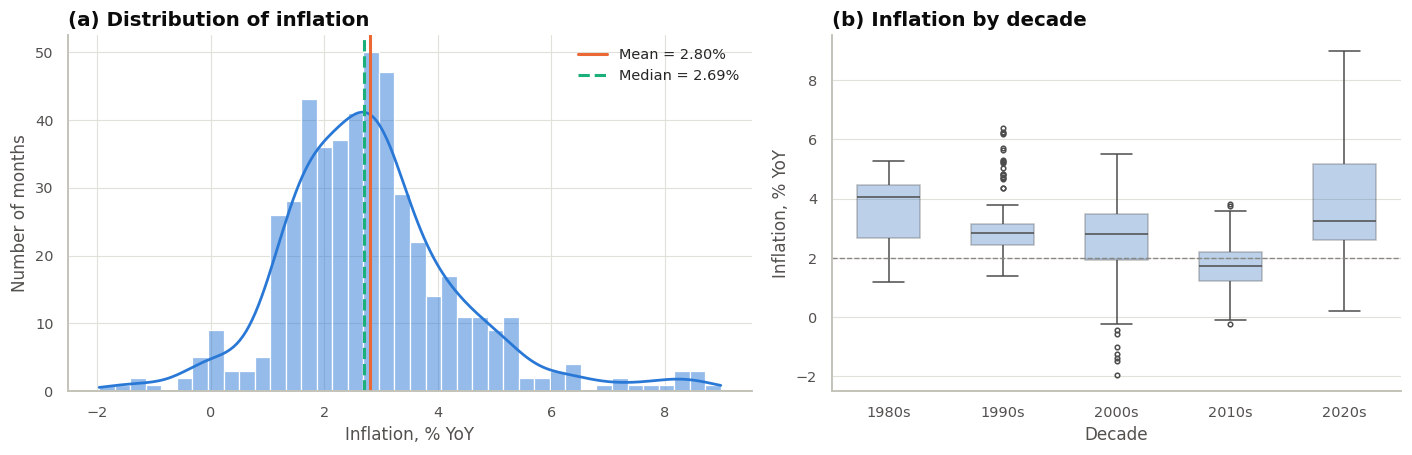

In [203]:
decade = pd.Index((inflation.index.year // 10 * 10).astype(str) + "s", name="Decade")
by_decade = inflation.groupby(decade).agg(["mean", "median", "std", "min", "max"]).round(2)
by_decade.columns = ["Mean %", "Median %", "Std", "Min %", "Max %"]
display(by_decade)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
sns.histplot(inflation.dropna(), bins=40, kde=True, color=PALETTE[0], edgecolor="white", ax=ax)
ax.axvline(inflation.mean(), color=PALETTE[1], lw=2, label=f"Mean = {inflation.mean():.2f}%")
ax.axvline(inflation.median(), color=PALETTE[2], lw=2, ls="--", label=f"Median = {inflation.median():.2f}%")
ax.set(title="(a) Distribution of inflation", xlabel="Inflation, % YoY", ylabel="Number of months")
ax.legend()

ax = axes[1]
sns.boxplot(x=np.asarray(decade), y=inflation.values, order=sorted(set(decade)), color=PALETTE[0], width=0.55,
            boxprops=dict(alpha=0.35), flierprops=dict(marker="o", markersize=3), ax=ax)
ax.axhline(2, color=MUTED, ls="--", lw=0.9)
ax.set(title="(b) Inflation by decade", xlabel="Decade", ylabel="Inflation, % YoY")
finish(fig, "inflation_distribution")

### 6.3 Feature distributions

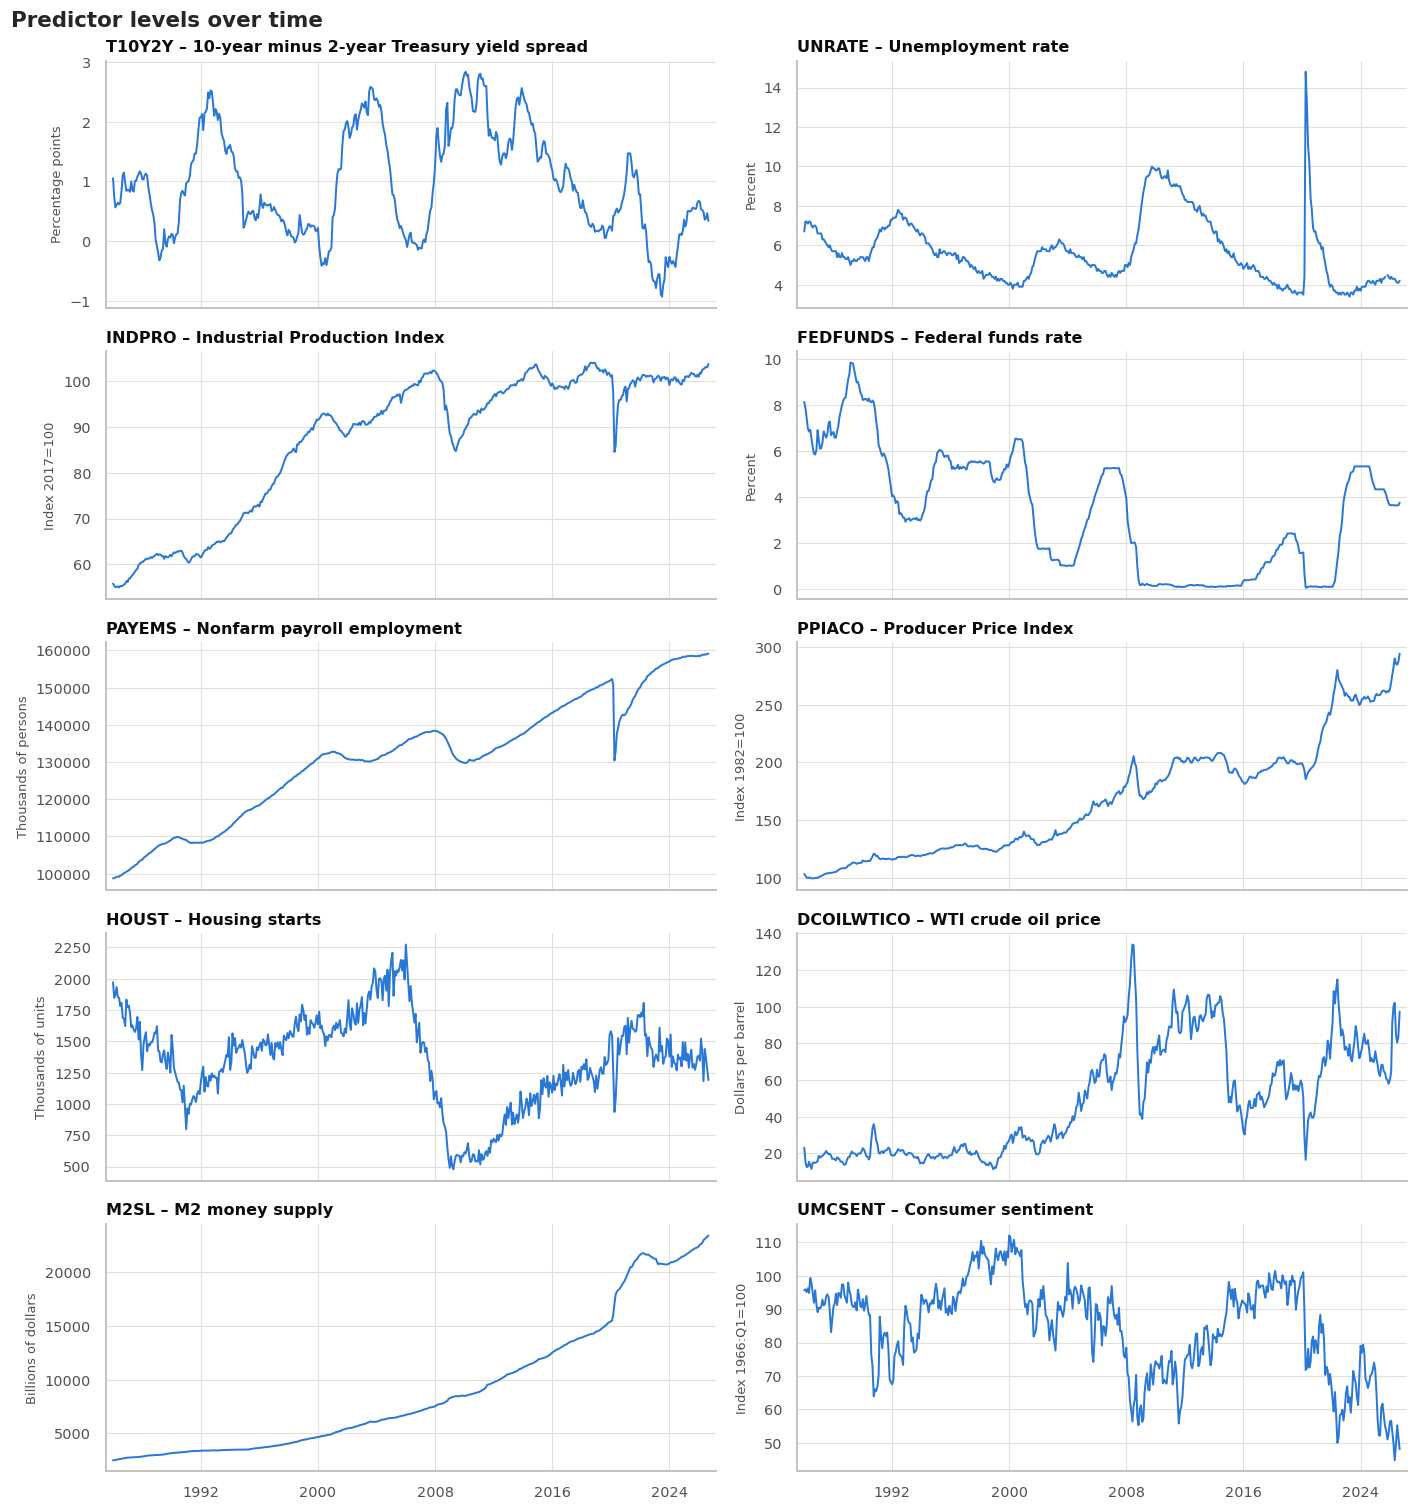

In [204]:
fig, axes = plt.subplots(5, 2, figsize=(13, 14), sharex=True)
for ax, sid in zip(axes.ravel(), PREDICTOR_SERIES):
    ax.plot(features.index, features[sid], color=PALETTE[0], lw=1.3)
    ax.set_title(f"{sid} – {SERIES_INFO[sid][0]}", fontsize=10.5)
    ax.set_ylabel(SERIES_INFO[sid][1], fontsize=8.5)
    format_year_axis(ax, step=8)
fig.suptitle("Predictor levels over time", x=0.01, ha="left", fontsize=14, fontweight="bold")
finish(fig, "raw_series")

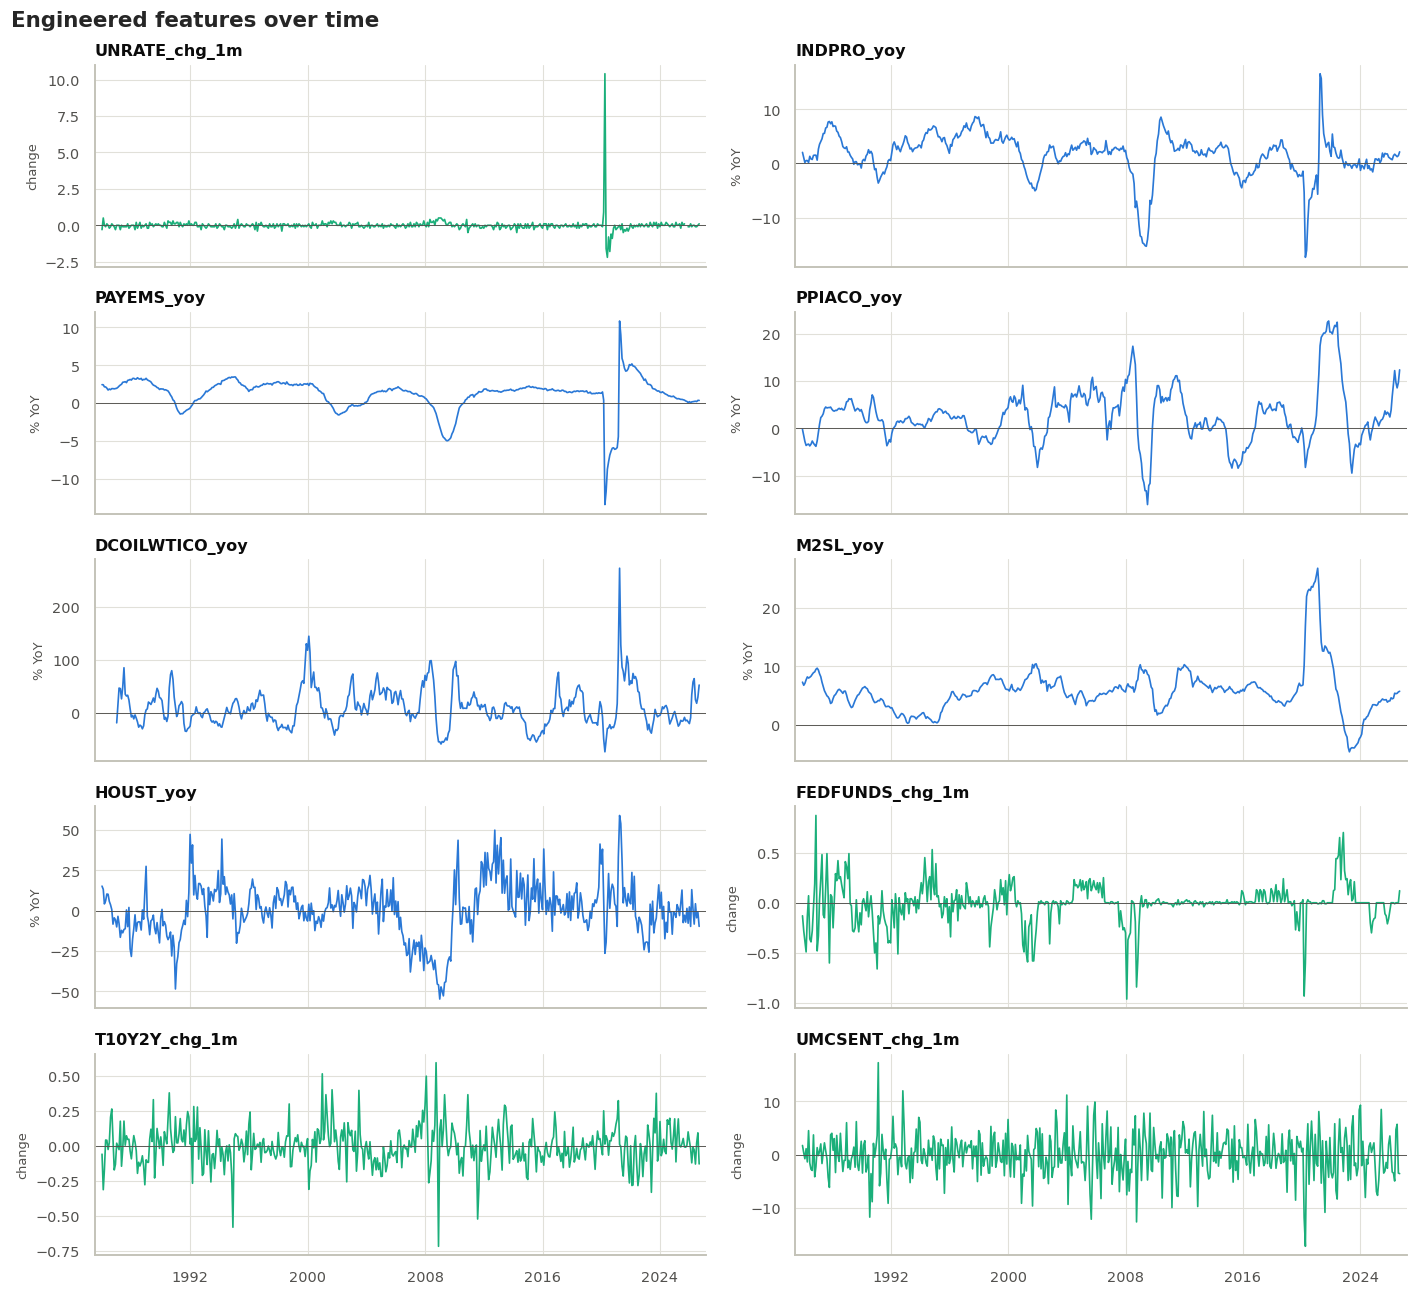

In [205]:
derived = [f for f in FEATURES if f not in PREDICTOR_SERIES]
nrows = int(np.ceil(len(derived) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(13, 2.4 * nrows), sharex=True)
for ax, f in zip(axes.ravel(), derived):
    ax.plot(features.index, features[f], color=PALETTE[2] if "chg" in f else PALETTE[0], lw=1.1)
    ax.axhline(0, color=INK_2, lw=0.6)
    ax.set_title(f, fontsize=10.5)
    ax.set_ylabel("change" if "chg" in f else "% YoY", fontsize=8.5)
    format_year_axis(ax, step=8)
for ax in axes.ravel()[len(derived):]:
    ax.set_visible(False)
fig.suptitle("Engineered features over time", x=0.01, ha="left", fontsize=14, fontweight="bold")
finish(fig, "engineered_series")

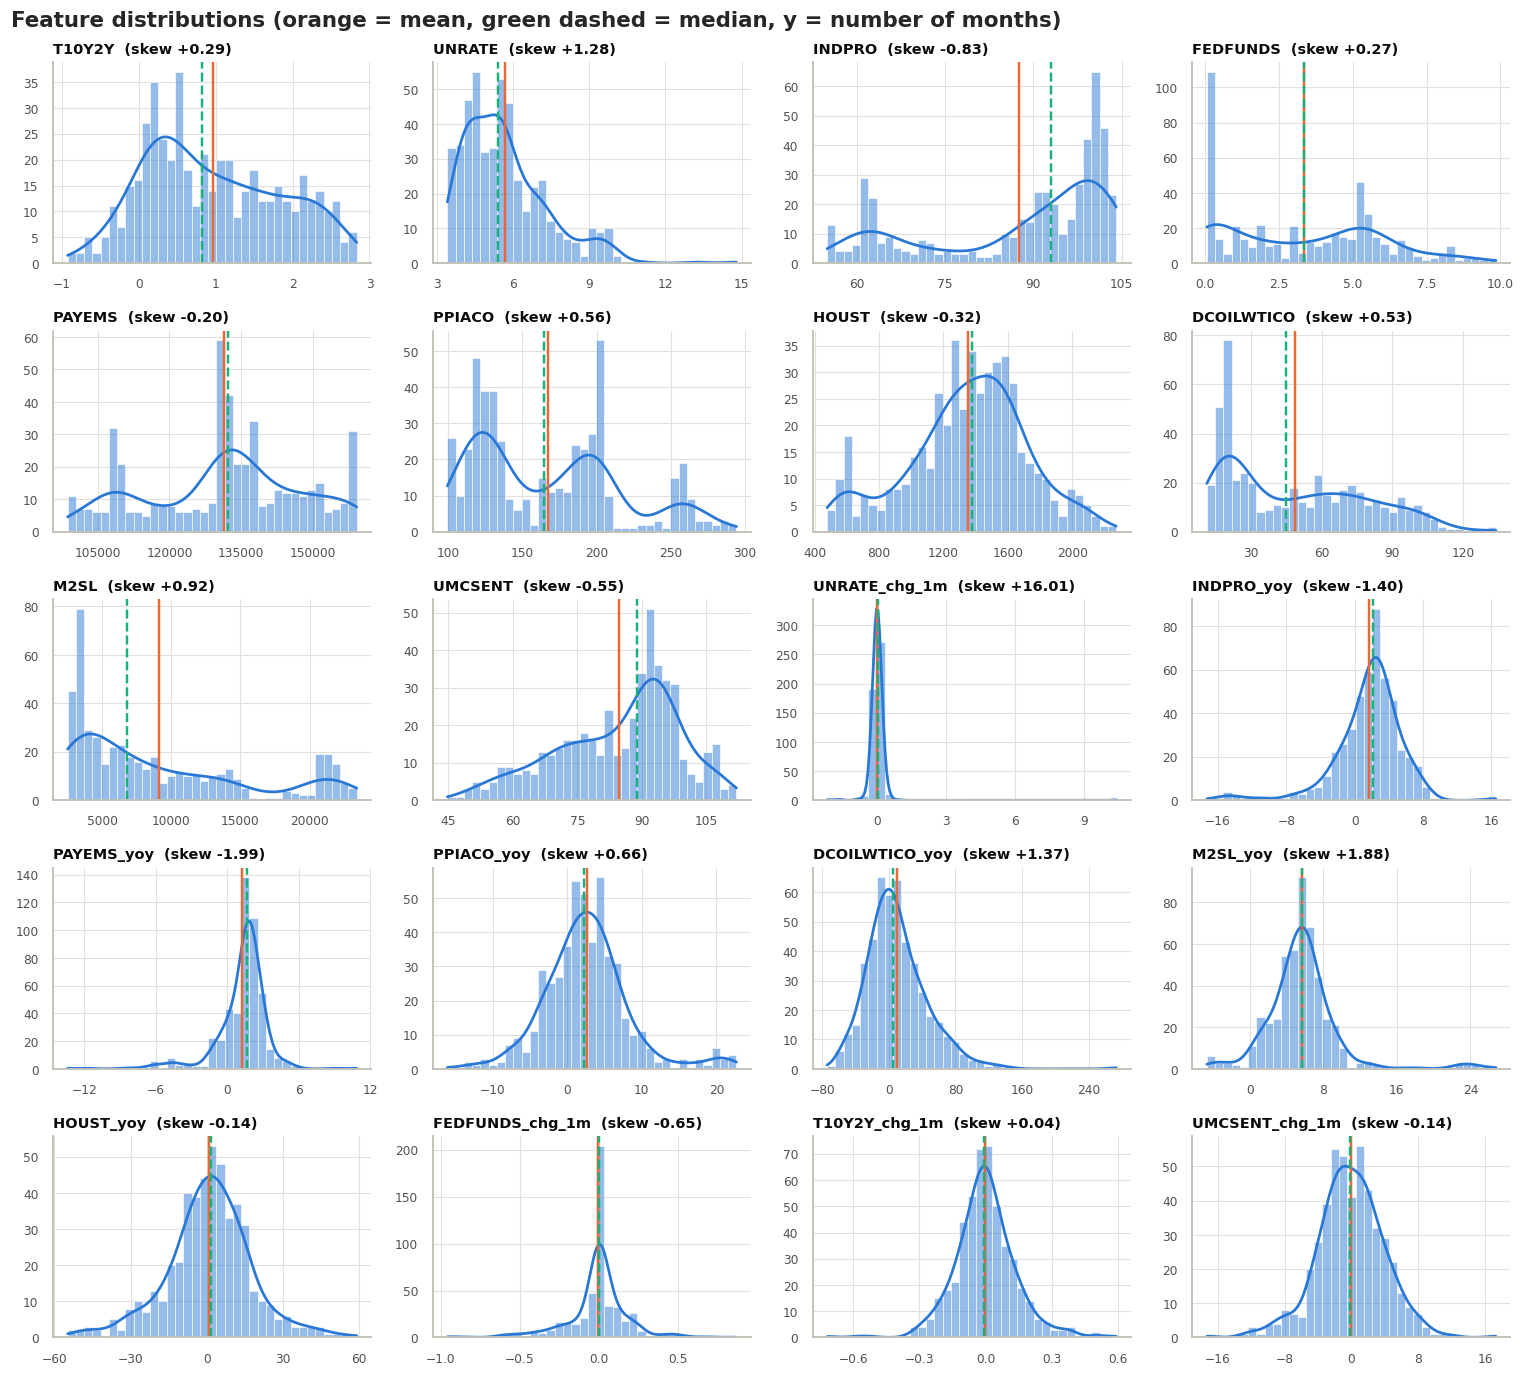

In [206]:
ncols = 4
nrows = int(np.ceil(len(FEATURES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.55 * nrows))
for ax, f in zip(axes.ravel(), FEATURES):
    x = features[f].dropna()
    sns.histplot(x, bins=35, kde=True, color=PALETTE[0], edgecolor="white", linewidth=0.4, ax=ax)
    ax.axvline(x.mean(), color=PALETTE[1], lw=1.6)
    ax.axvline(x.median(), color=PALETTE[2], lw=1.6, ls="--")
    ax.set_title(f"{f}  (skew {x.skew():+.2f})", fontsize=9.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.tick_params(labelsize=8)
for ax in axes.ravel()[len(FEATURES):]:
    ax.set_visible(False)
fig.suptitle("Feature distributions (orange = mean, green dashed = median, y = number of months)",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
finish(fig, "feature_histograms")

### Range, skewness and volatility

* Skewness: |skew| < 0.5 symmetric, 0.5–1 moderate, > 1 high.
* Volatility: standard deviation, and standard deviation of the month-to-month change.

In [207]:
dist = pd.DataFrame({
    "min": features.min(), "max": features.max(),
    "range": features.max() - features.min(),
    "mean": features.mean(), "median": features.median(), "std": features.std(),
    "skew": features.skew(),
    "monthly-change std": features.diff().std(),
})
dist["skew class"] = pd.cut(dist["skew"].abs(), [0, 0.5, 1, np.inf], labels=["Symmetric", "Moderate", "High"],
                            right=False)
display(dist.round(2))

,min,max,range,mean,median,std,skew,monthly-change std,skew class
T10Y2Y,-0.93,2.83,3.76,0.96,0.82,0.88,0.29,0.14,Symmetric
UNRATE,3.40,14.80,11.40,5.68,5.40,1.67,1.28,0.52,High
INDPRO,54.90,104.10,49.20,87.49,92.95,15.41,-0.83,0.89,Moderate
FEDFUNDS,0.05,9.85,9.80,3.35,3.34,2.63,0.27,0.20,Symmetric
PAYEMS,98732.00,159128.00,60396.00,131356.00,132234.00,16138.89,-0.20,991.82,Symmetric
PPIACO,99.30,294.47,195.17,167.30,164.30,49.37,0.56,2.07,Moderate
HOUST,478.00,2273.00,1795.00,1350.83,1380.00,367.55,-0.32,101.10,Symmetric
DCOILWTICO,11.34,133.88,122.54,48.79,44.72,29.55,0.53,4.92,Moderate
M2SL,2501.60,23413.90,20912.30,9121.90,6815.70,6267.98,0.92,81.74,Moderate
UMCSENT,44.80,112.00,67.20,84.69,88.80,14.14,-0.55,4.06,Moderate


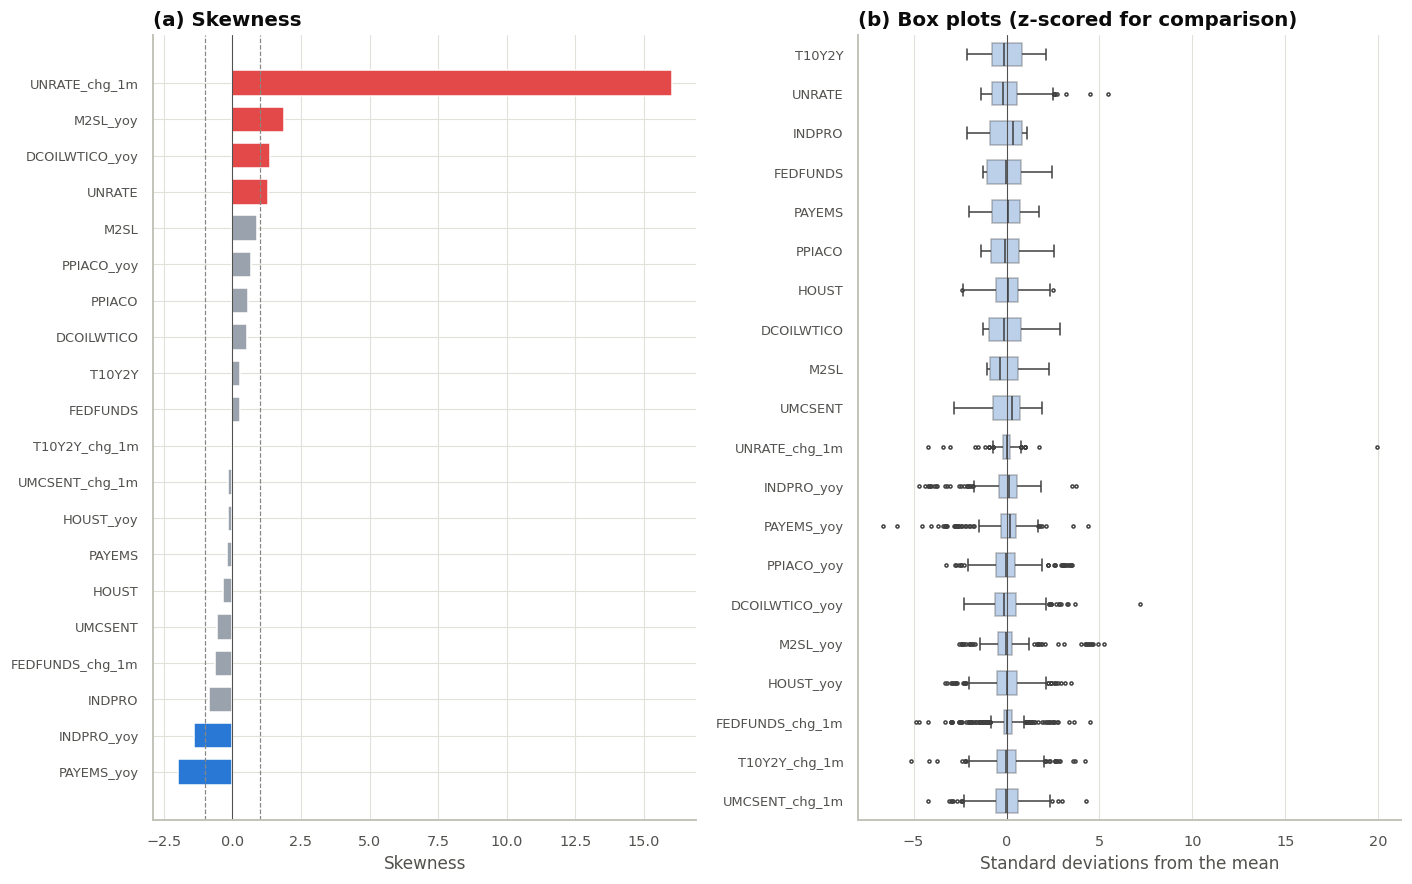

In [208]:
fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * len(FEATURES) + 1.8))
sk = dist["skew"].sort_values()
colors = [PALETTE[7] if v > 1 else (PALETTE[0] if v < -1 else "#9aa3ad") for v in sk]
axes[0].barh(sk.index, sk.values, color=colors, height=0.7)
for x in [-1, 1]:
    axes[0].axvline(x, color=MUTED, ls="--", lw=0.8)
axes[0].axvline(0, color=INK_2, lw=0.7)
axes[0].set(title="(a) Skewness", xlabel="Skewness")
axes[0].tick_params(axis="y", labelsize=8.5)

z = (features - features.mean()) / features.std()
sns.boxplot(data=z, orient="h", color=PALETTE[0], width=0.6, fliersize=2, boxprops=dict(alpha=0.35), ax=axes[1])
axes[1].axvline(0, color=INK_2, lw=0.7)
axes[1].set(title="(b) Box plots (z-scored for comparison)", xlabel="Standard deviations from the mean")
axes[1].tick_params(axis="y", labelsize=8.5)
finish(fig, "skew_and_boxplots")

### Possible outliers

* IQR rule: outside $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$
* Z-score rule: $|z| > 3$

Outliers are reported, not removed.

In [209]:
rows = []
for f in FEATURES:
    x = features[f]
    q1, q3 = x.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    z_abs = ((x - x.mean()) / x.std()).abs()
    extreme = z_abs.idxmax()
    rows.append({"Feature": f, "IQR lower": lo, "IQR upper": hi,
                 "IQR outliers": int(((x < lo) | (x > hi)).sum()), "|z| > 3": int((z_abs > 3).sum()),
                 "Most extreme month": ym(extreme), "Value": x[extreme]})
outliers = pd.DataFrame(rows).set_index("Feature").sort_values("IQR outliers", ascending=False)
display(outliers.round(2))

,IQR lower,IQR upper,IQR outliers,|z| > 3,Most extreme month,Value
Feature,,,,,,
FEDFUNDS_chg_1m,-0.17,0.18,119,9,Feb 2008,-0.96
M2SL_yoy,-0.55,11.50,37,12,Feb 2021,26.78
PAYEMS_yoy,-2.03,4.92,34,13,Apr 2020,-13.39
PPIACO_yoy,-9.50,14.17,27,13,Nov 2021,22.69
HOUST_yoy,-34.27,37.49,26,5,Apr 2021,59.08
INDPRO_yoy,-5.66,9.43,24,14,Apr 2020,-17.32
UNRATE_chg_1m,-0.40,0.40,23,4,Apr 2020,10.40
T10Y2Y_chg_1m,-0.29,0.28,22,6,Dec 2008,-0.72
DCOILWTICO_yoy,-75.97,91.31,13,4,Apr 2021,272.96


### 6.4 Contemporaneous correlations

Pearson correlation between each feature and inflation in the same month, using all months where both
values are available.

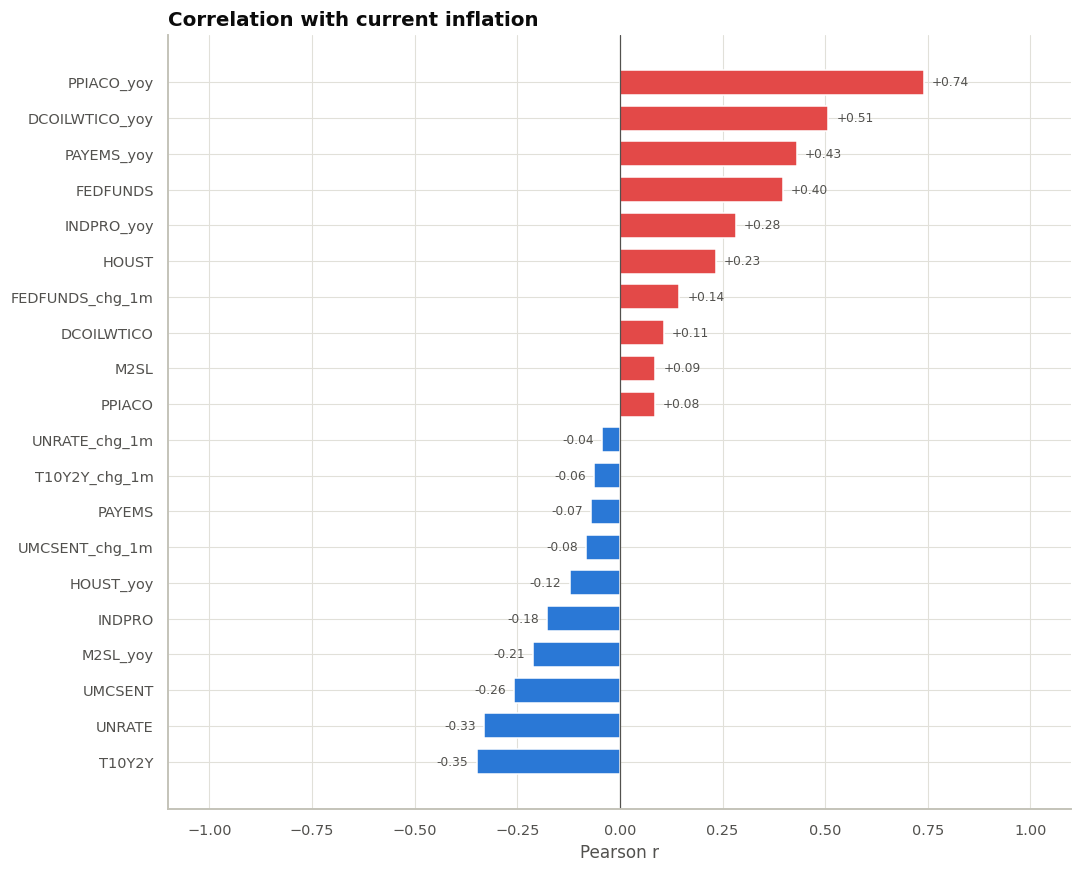

,r with current inflation
PPIACO_yoy,0.740
DCOILWTICO_yoy,0.508
PAYEMS_yoy,0.431
FEDFUNDS,0.397
T10Y2Y,-0.349
UNRATE,-0.331
INDPRO_yoy,0.283
UMCSENT,-0.258
HOUST,0.233
M2SL_yoy,-0.211


Highest correlation: PPIACO_yoy (r = +0.74)


In [210]:
corr_now = features.corrwith(inflation).sort_values()

fig, ax = plt.subplots(figsize=(10, 0.33 * len(FEATURES) + 1.5))
ax.barh(corr_now.index, corr_now.values, color=[PALETTE[7] if v > 0 else PALETTE[0] for v in corr_now], height=0.7)
for y, v in enumerate(corr_now.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=INK_2)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlim(-1.1, 1.1)
ax.set(title="Correlation with current inflation", xlabel="Pearson r")
finish(fig, "corr_current_inflation")

ranked = corr_now.reindex(corr_now.abs().sort_values(ascending=False).index)
display(ranked.rename("r with current inflation").to_frame().round(3))
print(f"Highest correlation: {ranked.index[0]} (r = {ranked.iloc[0]:+.2f})")

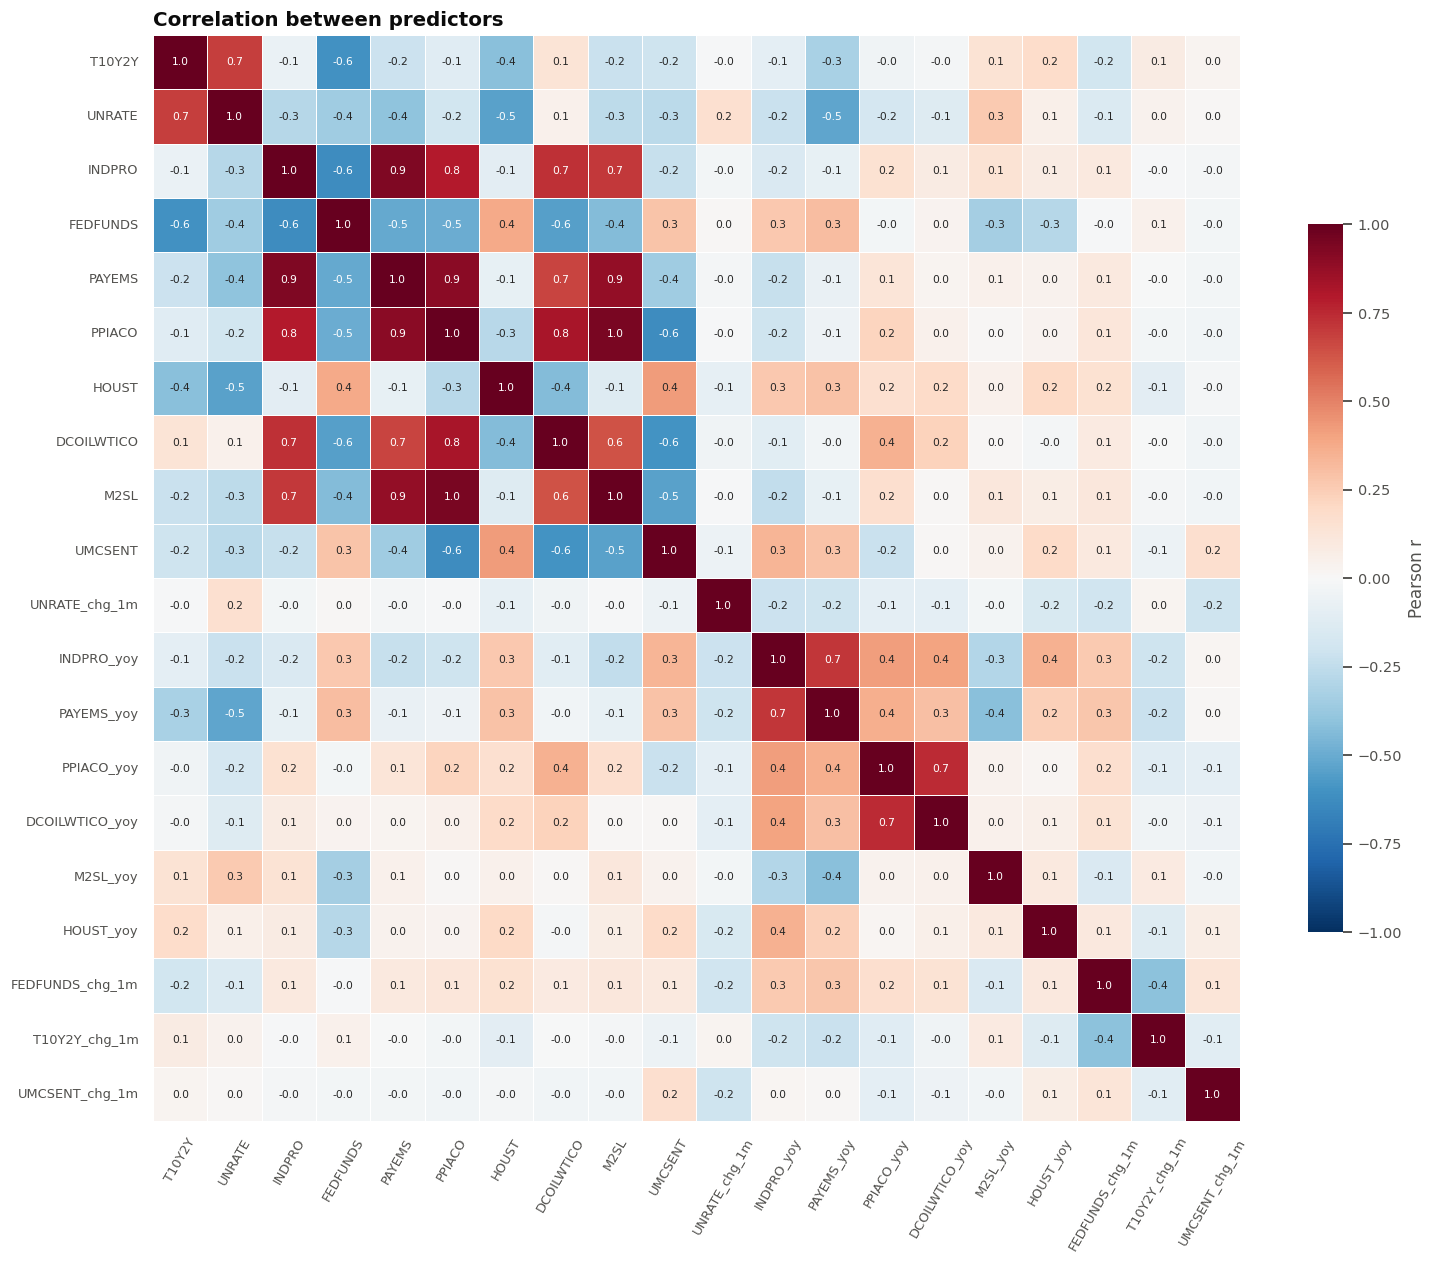

Predictor pairs with |r| >= 0.8:


r
PPIACO M2SL        0.95
INDPRO PAYEMS      0.94
PAYEMS PPIACO      0.90
       M2SL        0.88
PPIACO DCOILWTICO  0.82

In [211]:
pred_corr = features.corr()
n = len(FEATURES)
fig, ax = plt.subplots(figsize=(0.55 * n + 3, 0.5 * n + 2))
sns.heatmap(pred_corr, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white", square=True,
            cbar_kws={"label": "Pearson r", "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.set_title("Correlation between predictors")
ax.tick_params(axis="x", rotation=60, labelsize=8.5)
ax.tick_params(axis="y", labelsize=8.5)
finish(fig, "predictor_corr_heatmap")

upper = pred_corr.where(np.triu(np.ones_like(pred_corr, dtype=bool), k=1)).stack()
strong = upper[upper.abs() >= 0.8].sort_values(key=abs, ascending=False)
print("Predictor pairs with |r| >= 0.8:")
display(strong.rename("r").round(2).to_frame())

### 6.5 Lead-lag analysis

Correlation between each feature at month *t* and inflation at *t + n*, i.e.
$\text{corr}(X_t, \text{Inflation}_{t+n})$ for *n* = 1, 3, 6, 12. *t + 0* is shown for reference.

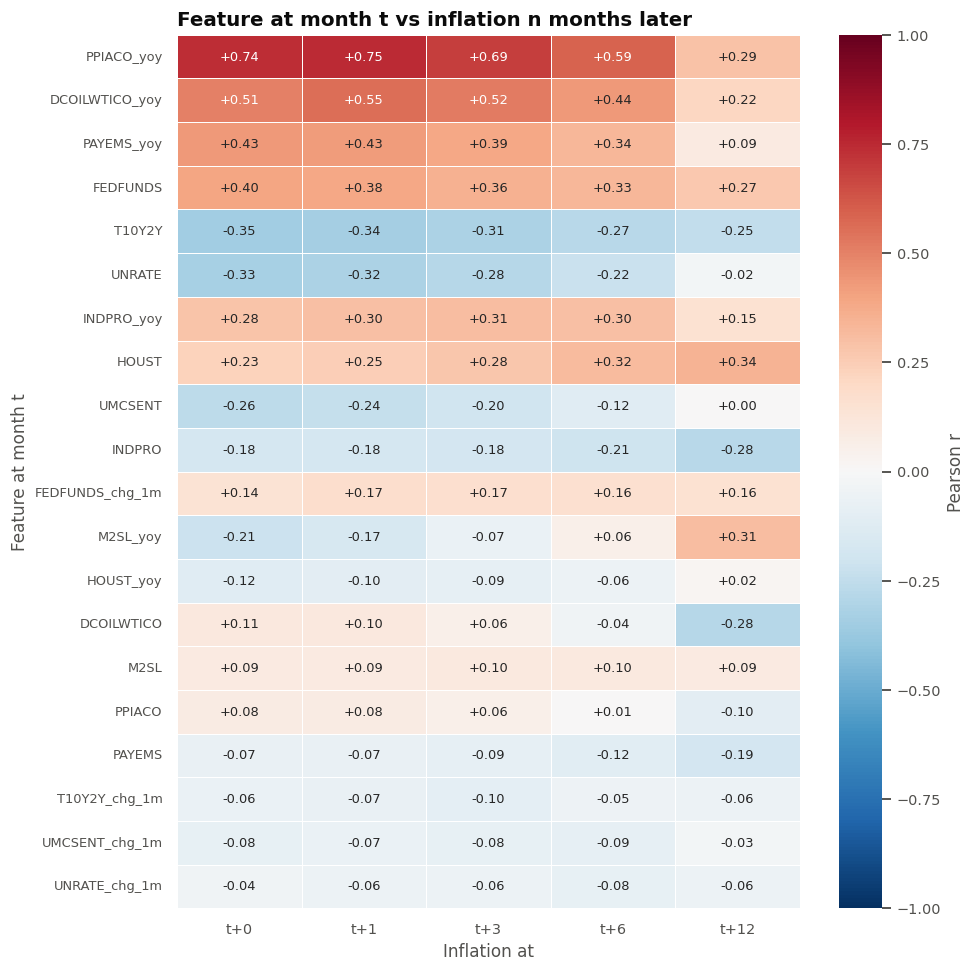

In [212]:
lead_lag = pd.DataFrame({"t+0": features.corrwith(inflation)})
for h in HORIZONS:
    lead_lag[f"t+{h}"] = features.corrwith(targets[f"target_{h}m"])
lead_lag = lead_lag.reindex(lead_lag["t+1"].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(9, 0.36 * len(FEATURES) + 1.8))
sns.heatmap(lead_lag, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt="+.2f",
            annot_kws={"size": 8.5}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Pearson r"}, ax=ax)
ax.grid(False)
ax.set(title="Feature at month t vs inflation n months later", xlabel="Inflation at", ylabel="Feature at month t")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", labelsize=8.5)
finish(fig, "lead_lag_heatmap")

In [213]:
TOP_K = 5
ranking = {}
for col in lead_lag.columns[1:]:
    r = lead_lag[col].reindex(lead_lag[col].abs().sort_values(ascending=False).index).head(TOP_K)
    ranking[col] = [f"{name} ({val:+.2f})" for name, val in r.items()]
display(pd.DataFrame(ranking, index=pd.RangeIndex(1, TOP_K + 1, name="Rank")))

print("Best single indicator per horizon:")
for col in lead_lag.columns[1:]:
    best = lead_lag[col].abs().idxmax()
    print(f"  {col:5s} {best:16s} r = {lead_lag.loc[best, col]:+.2f}")

,t+1,t+3,t+6,t+12
Rank,,,,
1,PPIACO_yoy (+0.75),PPIACO_yoy (+0.69),PPIACO_yoy (+0.59),HOUST (+0.34)
2,DCOILWTICO_yoy (+0.55),DCOILWTICO_yoy (+0.52),DCOILWTICO_yoy (+0.44),M2SL_yoy (+0.31)
3,PAYEMS_yoy (+0.43),PAYEMS_yoy (+0.39),PAYEMS_yoy (+0.34),PPIACO_yoy (+0.29)
4,FEDFUNDS (+0.38),FEDFUNDS (+0.36),FEDFUNDS (+0.33),DCOILWTICO (-0.28)
5,T10Y2Y (-0.34),T10Y2Y (-0.31),HOUST (+0.32),INDPRO (-0.28)


Best single indicator per horizon:
  t+1   PPIACO_yoy       r = +0.75
  t+3   PPIACO_yoy       r = +0.69
  t+6   PPIACO_yoy       r = +0.59
  t+12  HOUST            r = +0.34


## 7. Preprocessing and regression modelling

The following sections describe the preprocessing and modelling approach used for the inflation forecasting task.

The workflow includes IQR-based outlier capping, median imputation, feature standardisation, and five regression models: Linear Regression, Ridge, Lasso, Elastic Net, and K-Nearest Neighbours (KNN). Pipelines are used for preprocessing and model fitting, with hyperparameters selected based on validation performance.

All preprocessing steps are fitted using training data to prevent data leakage. The test set is reserved for the final evaluation of the selected models.

In [214]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


### 7.1 Data Selection and Chronological Splitting

All 20 engineered features are considered as candidate predictors. Rows with missing values in any of these features or in the corresponding future inflation target are removed before modelling. This primarily affects the first 12 months, due to missing `DCOILWTICO_yoy` values, and the months around the October 2025 gap in `UNRATE`. The imputer is retained in the pipelines as a precaution, although no missing values remain after this filtering step.

The data is then divided chronologically into training, validation and test sets. A gap equal to the forecasting horizon is maintained between consecutive sets to prevent overlap between the target periods.

In [215]:
rows_before = len(data)
incomplete = data[FEATURES].isna().any(axis=1)
dropped_months = data.index[incomplete]
data = data.loc[~incomplete].copy()

print(f"Rows before: {rows_before} | dropped: {int(incomplete.sum())} | kept: {len(data)}")
print(f"Dropped months: {', '.join(map(ym, dropped_months)) or 'None'}")
print(f"Missing predictor values left: {int(data[FEATURES].isna().sum().sum())}")

Rows before: 489 | dropped: 14 | kept: 475
Dropped months: Jan 1986, Feb 1986, Mar 1986, Apr 1986, May 1986, Jun 1986, Jul 1986, Aug 1986, Sep 1986, Oct 1986, Nov 1986, Dec 1986, Oct 2025, Nov 2025
Missing predictor values left: 0


In [216]:
TRAIN_FRAC = 0.60
VAL_FRAC = 0.20

def chronological_split_with_gap(model_data, horizon):
    model_data = model_data.sort_index()
    train_boundary_position = int(len(model_data) * TRAIN_FRAC)
    val_boundary_position = int(len(model_data) * (TRAIN_FRAC + VAL_FRAC))
    train_cutoff = model_data.index[train_boundary_position]
    val_cutoff = model_data.index[val_boundary_position]
    target_dates = model_data.index + pd.DateOffset(months=horizon)
    train_mask = ((model_data.index < train_cutoff) &(target_dates < train_cutoff))
    val_mask = ((model_data.index >= train_cutoff) &(model_data.index < val_cutoff) &(target_dates < val_cutoff))
    test_mask = model_data.index >= val_cutoff
    train = model_data.loc[train_mask].copy()
    val = model_data.loc[val_mask].copy()
    test = model_data.loc[test_mask].copy()
    return train, val, test


def calculate_metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),"R2": r2_score(y_true, y_pred)}


### 7.2 IQR-based outlier capping

Extreme predictor values are capped using the IQR method. For each feature, the lower and upper bounds are calculated from the training data and applied consistently to the validation and test data. No observations are removed during this process. Missing values are left unchanged and handled later through imputation in the model pipeline.

In [217]:
def get_iqr_bounds(X_train):
    q1 = X_train.quantile(0.25)
    q3 = X_train.quantile(0.75)
    iqr = q3 - q1
    lower_bounds = q1 - (1.5*iqr)
    upper_bounds = q3 + (1.5*iqr)
    return lower_bounds, upper_bounds


def apply_iqr_capping(X, lower_bounds, upper_bounds):
    return X.clip(lower=lower_bounds, upper=upper_bounds, axis=1)


### 7.3 Regression Pipelines and Hyperparameter Tuning

Each model pipeline performs imputation followed by standardisation and regression. The imputer and scaler are fitted on the training data during each model fit, ensuring that information from the validation and test sets is not used during preprocessing.

All 20 features are initially considered by the candidate models. Lasso and Elastic Net regularisation can reduce some coefficients to zero, indicating which features are not retained by the respective models.

In [218]:
def build_candidates():
    return {"LinearRegression": (Pipeline([("impute", SimpleImputer(strategy="median")),("scale", StandardScaler()),("model", LinearRegression())]),
            {"impute__strategy": ["mean", "median"]}),
            "Ridge": (Pipeline([("impute", SimpleImputer(strategy="median")),("scale", StandardScaler()),("model", Ridge())]),
            {"model__alpha": np.logspace(-2, 3, 25)}),
            "Lasso": (Pipeline([("impute", SimpleImputer(strategy="median")),("scale", StandardScaler()),("model", Lasso(max_iter=50000))]),
            {"model__alpha": np.logspace(-3, 1, 25)}),
            "ElasticNet": (Pipeline([("impute", SimpleImputer(strategy="median")),("scale", StandardScaler()),("model", ElasticNet(max_iter=50000))]),
            {"model__alpha": np.logspace(-3, 1, 15),"model__l1_ratio": [0.2, 0.5, 0.8]}),
            "KNN": (Pipeline([("impute", SimpleImputer(strategy="median")),("scale", StandardScaler()),("model", KNeighborsRegressor())]),
            {"model__n_neighbors": [3, 5, 9, 15, 25],"model__weights": ["uniform", "distance"]})}


### 7.4 Evaluation Metrics

The regression models are evaluated using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and the coefficient of determination ($R^2$).

**1. Root Mean Squared Error (RMSE)**

$$
RMSE = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}
$$

**2. Mean Absolute Error (MAE)**

$$
MAE = \frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|
$$

**3. Coefficient of Determination ($R^2$)**

$$
R^2 = 1-\frac{\sum_{i=1}^{N}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{N}(y_i-\bar{y})^2}
$$

Here:

- $N$ is the number of observations.
- $y_i$ is the actual inflation value.
- $\hat{y}_i$ is the predicted inflation value.
- $\bar{y}$ is the mean of the actual inflation values.

### 7.5 Model Tuning, Feature Selection and Evaluation

For each forecast horizon, the observations with available target values are split chronologically into training, validation, and test sets. IQR capping bounds are calculated using the training predictors and applied to the validation data. Each candidate model is tuned using the training and validation sets, and the model with the lowest validation RMSE is selected.

The selected model is then refitted using the combined training and validation data. The IQR bounds are recalculated using this combined data and applied unchanged to the test predictors. Finally, the model is evaluated on the test set.

A training-mean baseline is included for comparison. The non-zero coefficients from Lasso are also reported to show the features retained by Lasso regularisation at each forecast horizon.

In [219]:
validation_records = []
test_records = []
selected_models = {}
coefficient_records = []
lasso_feature_records = []

for horizon in HORIZONS:
    target_column = f"target_{horizon}m"
    horizon_data = data.dropna(subset=[target_column]).copy()
    train, val, test = chronological_split_with_gap(horizon_data, horizon)
    X_train_raw = train[FEATURES]
    y_train = train[target_column]
    X_val_raw = val[FEATURES]
    y_val = val[target_column]
    X_test_raw = test[FEATURES]
    y_test = test[target_column]
    print(f"\n{horizon}-month horizon")
    print(f"Train: {train.index.min():%Y-%m} to {train.index.max():%Y-%m} ({len(train)} rows)")
    print(f"Validation: {val.index.min():%Y-%m} to {val.index.max():%Y-%m} ({len(val)} rows)")
    print(f"Test: {test.index.min():%Y-%m} to {test.index.max():%Y-%m} ({len(test)} rows)")
    lower_train, upper_train = get_iqr_bounds(X_train_raw)
    X_train = apply_iqr_capping(X_train_raw, lower_train, upper_train)
    X_val = apply_iqr_capping(X_val_raw, lower_train, upper_train)
    X_train_val = pd.concat([X_train, X_val])
    y_train_val = pd.concat([y_train, y_val])
    validation_split = [(np.arange(len(X_train)),np.arange(len(X_train), len(X_train_val)))]
    horizon_results = []
    candidates = build_candidates()

    for model_name, (pipeline, parameter_grid) in candidates.items():
        if model_name == "KNN":
            valid_neighbors = [k for k in [3, 5, 9, 15, 25] if k <= len(X_train)]
            parameter_grid = {"model__n_neighbors": valid_neighbors, "model__weights": ["uniform", "distance"]}
        grid_search = GridSearchCV(estimator=pipeline,param_grid=parameter_grid,cv=validation_split,scoring="neg_root_mean_squared_error",refit=False)
        grid_search.fit(X_train_val, y_train_val)
        validation_model = pipeline.set_params(**grid_search.best_params_)
        validation_model.fit(X_train, y_train)
        validation_prediction = validation_model.predict(X_val)
        validation_metrics = calculate_metrics(y_val, validation_prediction)
        validation_records.append({"Horizon": horizon,"Model": model_name,**validation_metrics,"Best parameters": grid_search.best_params_})
        horizon_results.append({"Model": model_name,"Pipeline": pipeline,"Best parameters": grid_search.best_params_,
                                "Validation RMSE": validation_metrics["RMSE"]})


    baseline_val_prediction = np.full(len(y_val), y_train.mean())
    baseline_val_metrics = calculate_metrics(y_val, baseline_val_prediction)
    validation_records.append({"Horizon": horizon,"Model": "TrainMean",**baseline_val_metrics,"Best parameters": {}})
    best_result = min(horizon_results,key=lambda result: result["Validation RMSE"])
    best_name = best_result["Model"]
    lower_train_val, upper_train_val = get_iqr_bounds(pd.concat([X_train_raw, X_val_raw]))
    X_train_val_raw = pd.concat([X_train_raw, X_val_raw])
    X_train_val_capped = apply_iqr_capping(X_train_val_raw, lower_train_val, upper_train_val)
    X_test_capped = apply_iqr_capping(X_test_raw, lower_train_val, upper_train_val)
    best_pipeline = best_result["Pipeline"].set_params(**best_result["Best parameters"])
    final_model = best_pipeline.fit(X_train_val_capped, y_train_val)
    test_prediction = final_model.predict(X_test_capped)
    test_metrics = calculate_metrics(y_test, test_prediction)
    test_records.append({"Horizon": horizon,"Selected model": best_name,**test_metrics})
    baseline_test_prediction = np.full(len(y_test), y_train_val.mean())
    baseline_test_metrics = calculate_metrics(y_test, baseline_test_prediction)
    test_records.append({"Horizon": horizon,"Selected model": "TrainMean baseline",**baseline_test_metrics})
    selected_models[horizon] = {"name": best_name,"model": final_model,"lower_bounds": lower_train_val,"upper_bounds": upper_train_val}    
    linear_results = [result for result in horizon_results if result["Model"] in ["LinearRegression", "Ridge", "Lasso", "ElasticNet"]]
    best_linear = min(linear_results, key=lambda result: result["Validation RMSE"])
    linear_pipeline = best_linear["Pipeline"].set_params(**best_linear["Best parameters"])
    linear_pipeline.fit(X_train_val_capped, y_train_val)
    coefficients = linear_pipeline.named_steps["model"].coef_

    for feature, coefficient in zip(FEATURES, coefficients):
        coefficient_records.append({"Horizon": horizon, "Linear model": best_linear["Model"],"Feature": feature,"Coefficient": coefficient,
                                    "Absolute coefficient": abs(coefficient)})

    lasso_result = next(result for result in horizon_results if result["Model"] == "Lasso")
    lasso_pipeline = lasso_result["Pipeline"].set_params(**lasso_result["Best parameters"])
    lasso_pipeline.fit(X_train_val_capped, y_train_val)
    lasso_coefficients = lasso_pipeline.named_steps["model"].coef_
    selected_features = [feature for feature, coefficient in zip(FEATURES, lasso_coefficients) if not np.isclose(coefficient, 0.0)]
    lasso_feature_records.append({"Horizon": horizon, "Selected feature count": len(selected_features), "Selected features": selected_features})



1-month horizon
Train: 1987-01 to 2010-06 (282 rows)
Validation: 2010-08 to 2018-05 (94 rows)
Test: 2018-07 to 2026-08 (95 rows)

3-month horizon
Train: 1987-01 to 2010-03 (279 rows)
Validation: 2010-07 to 2018-01 (91 rows)
Test: 2018-05 to 2026-06 (95 rows)

6-month horizon
Train: 1987-01 to 2009-10 (274 rows)
Validation: 2010-05 to 2017-08 (88 rows)
Test: 2018-03 to 2026-03 (94 rows)

12-month horizon
Train: 1987-01 to 2009-02 (266 rows)
Validation: 2010-03 to 2016-11 (81 rows)
Test: 2017-12 to 2025-09 (93 rows)


### 7.6 Results tables and selected features

In [ ]:
validation_df = pd.DataFrame(validation_records)
test_df = pd.DataFrame(test_records)
coefficients_df = pd.DataFrame(coefficient_records)
lasso_features_df = pd.DataFrame(lasso_feature_records)

print("\nValidation RMSE for all candidate models:")
display(validation_df.pivot(index="Model", columns="Horizon", values="RMSE").round(3))

print("\nSelected model for each forecasting horizon:")
selected_summary = pd.DataFrame([{"Horizon": horizon, "Selected model": selected_models[horizon]["name"]} for horizon in HORIZONS])
display(selected_summary)

print("\nFinal test performance:")
display(test_df.set_index(["Horizon", "Selected model"]).round(3))

print("\nFeatures retained by Lasso regularisation:")
display(lasso_features_df)

print("\nLargest non-zero standardized coefficients from the best linear model (zero coefficients dropped):")
for horizon in HORIZONS:
    print(f"\n{horizon}-month horizon:")
    top_features = (coefficients_df[(coefficients_df["Horizon"] == horizon) & (coefficients_df["Absolute coefficient"] > 0)].sort_values("Absolute coefficient", ascending=False).head(5))
    display(top_features[["Linear model", "Feature", "Coefficient", "Absolute coefficient"]].round(4))

print("\nThe coefficients describe associations in the fitted models, not causal effects. Correlated predictors can affect individual coefficient" 
        "magnitudes.")



Validation RMSE for all candidate models:


Horizon,1,3,6,12
Model,,,,
ElasticNet,0.483,0.600,0.760,0.945
KNN,1.070,1.274,1.490,1.772
Lasso,0.479,0.607,0.756,0.950
LinearRegression,2.216,1.638,1.735,4.525
Ridge,0.612,0.665,0.773,1.008
TrainMean,1.544,1.565,1.579,1.589



Selected model for each forecasting horizon:


,Horizon,Selected model
0,1,Lasso
1,3,ElasticNet
2,6,Lasso
3,12,ElasticNet



Final test performance:


MAE   RMSE     R2
Horizon Selected model                         
1       Lasso               1.326  2.039  0.112
        TrainMean baseline  1.611  2.358 -0.187
3       ElasticNet          1.607  2.303 -0.135
        TrainMean baseline  1.605  2.355 -0.187
6       Lasso               1.711  2.524 -0.345
        TrainMean baseline  1.598  2.358 -0.174
12      ElasticNet          2.096  2.940 -0.824
        TrainMean baseline  1.635  2.382 -0.197

... (7 outputs left out)

,Linear model,Feature,Coefficient,Absolute coefficient
43,Lasso,FEDFUNDS,0.507,0.507
44,Lasso,PAYEMS,-0.242,0.242
53,Lasso,PPIACO_yoy,0.202,0.202
54,Lasso,DCOILWTICO_yoy,0.151,0.151



12-month horizon:


,Linear model,Feature,Coefficient,Absolute coefficient
63,ElasticNet,FEDFUNDS,0.267,0.267
64,ElasticNet,PAYEMS,-0.170,0.170
65,ElasticNet,PPIACO,-0.153,0.153
67,ElasticNet,DCOILWTICO,-0.063,0.063
77,ElasticNet,FEDFUNDS_chg_1m,0.044,0.044



The coefficients describe associations in the fitted models, not causal effects. Correlated predictors can affect individual coefficientmagnitudes.


### 7.7 Model comparison plots

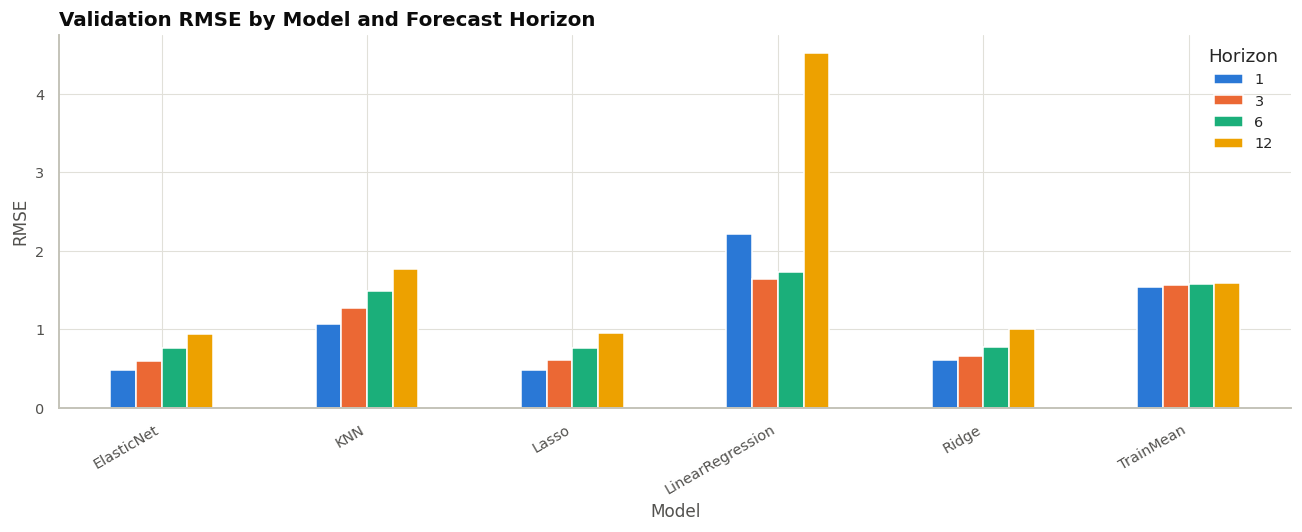

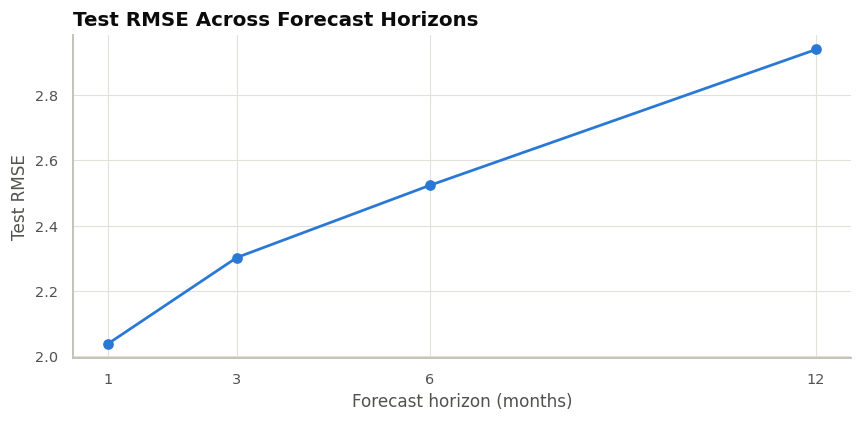

In [221]:
validation_plot = validation_df.pivot(index="Model", columns="Horizon", values="RMSE")
validation_plot.plot(kind="bar", figsize=(12, 5))
plt.title("Validation RMSE by Model and Forecast Horizon")
plt.ylabel("RMSE")
plt.xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

selected_test = test_df[test_df["Selected model"] != "TrainMean baseline"]

plt.figure(figsize=(8, 4))
plt.plot(selected_test["Horizon"],selected_test["RMSE"],marker="o",label="Selected model")
plt.xlabel("Forecast horizon (months)")
plt.ylabel("Test RMSE")
plt.title("Test RMSE Across Forecast Horizons")
plt.xticks(HORIZONS)
plt.tight_layout()
plt.show()


### 7.8 No-Change Benchmark
The training-mean baseline may be insufficient for inflation forecasting because year-over-year inflation tends to change gradually, and the current inflation rate is already known at month t. Therefore, an additional baseline is considered, which assumes that inflation n months ahead will remain at its current level. This baseline does not require any model fitting or parameter estimation. Its performance is evaluated on the test set, just like the training-mean baseline.

In [222]:
benchmark_records = []
for horizon in HORIZONS:
    target_column = f"target_{horizon}m"
    horizon_data = data.dropna(subset=[target_column])
    test_h = chronological_split_with_gap(horizon_data, horizon)[2]
    test_h = test_h.loc[test_h["inflation"].notna()]
    metrics = calculate_metrics(test_h[target_column], test_h["inflation"])
    benchmark_records.append({"Horizon": horizon, "Test rows": len(test_h), **metrics})

benchmark_df = pd.DataFrame(benchmark_records)
print("No-change forecast on the same test rows as the selected models:")
display(benchmark_df.round(3))

No-change forecast on the same test rows as the selected models:


,Horizon,Test rows,MAE,RMSE,R2
0,1,95,0.323,0.433,0.960
1,3,95,0.728,0.986,0.792
2,6,94,1.121,1.547,0.494
3,12,93,1.917,2.630,-0.459


## 8. Summary, Interpretation, Model Comparison and Conclusion

### 8.1 Summary of Data and Exploratory Analysis

**Dataset**
- The analysis covers January 1986 to September 2026, comprising 489 monthly observations.
- The dataset contains 20 engineered predictor features, consisting of 10 original macroeconomic variables and 10 derived features.
- Missing values mainly arise from the initial 12-month period of `DCOILWTICO_yoy`, the October 2025 gaps in `UNRATE` and CPI, and the unavailable future target values at the end of the dataset.

**Inflation Trends**
- The mean year-over-year CPI inflation over the study period is 2.80%, with a median of 2.69%.
- Inflation ranges from -1.96% in July 2009 to 8.98% in June 2022.
- Inflation remained in the moderate range (2–4%) during approximately 53% of the observed months, while 27% of the months recorded low inflation (0–2%) and 17% recorded high inflation (4% or above).
- Major periods of elevated inflation include 1987–1991, 2007–2008, and 2021–2023. The largest changes in inflation occurred around 2008–2010 and 2021–2023.

**Feature Behaviour and Correlations**
- `UNRATE_chg_1m` exhibits the highest skewness, largely due to its unusually large increase in April 2020.
- Several growth-related features contain extreme observations, particularly around the 2008–2009 financial crisis and the 2020–2023 period.
- Strong correlations exist among some predictor variables. For example, the correlation between `PPIACO` and `M2SL` is 0.95, while that between `INDPRO` and `PAYEMS` is 0.94.
- `PPIACO_yoy` has the strongest contemporaneous correlation with inflation (r = +0.74), followed by `DCOILWTICO_yoy`.
- In the lead-lag analysis, `PPIACO_yoy` is the strongest individual indicator for the 1-, 3-, and 6-month forecasting horizons, with correlations of +0.75, +0.69, and +0.59, respectively. For the 12-month horizon, `HOUST` has the highest correlation (+0.34).
- The correlations between individual predictors and future inflation generally weaken as the forecasting horizon increases.


### 8.2 Model Comparison

Validation RMSE for all candidate models and the training-mean baseline.

In [223]:
val_rmse = validation_df.pivot(index="Model", columns="Horizon", values="RMSE")
display(val_rmse.round(3))

candidates_only = val_rmse.drop(index="TrainMean")
regularised = ["Ridge", "Lasso", "ElasticNet"]

print()
for h in HORIZONS:
    ranked = candidates_only[h].sort_values()
    best, runner_up = ranked.index[0], ranked.index[1]
    extra = 100 * (ranked.iloc[1] / ranked.iloc[0] - 1)
    print(f"{h:>2}-month horizon: {best} has the lowest validation RMSE ({ranked.iloc[0]:.3f});"
          f"{runner_up} is next at {ranked.iloc[1]:.3f}, {extra:.0f}% higher.")

winners = [candidates_only[h].idxmin() for h in HORIZONS]
print()
if all(w in regularised for w in winners):
    print("A regularised linear model (Ridge, Lasso or Elastic Net) is the best candidate at every horizon.")
else:
    print("Best candidate by horizon: " + ", ".join(f"{h}m {w}" for h, w in zip(HORIZONS, winners)) + ".")

best_regularised = val_rmse.loc[regularised].min()
cut = 100 * (1 - best_regularised / val_rmse.loc["LinearRegression"])
print("Best regularised model versus plain Linear Regression, validation RMSE lower by: "+ ", ".join(f"{h}m {cut[h]:.0f}%" for h in HORIZONS) + ".")

for m in candidates_only.index:
    worse = [h for h in HORIZONS if candidates_only.loc[m, h] >= val_rmse.loc["TrainMean", h]]
    if worse:
        print(f"{m} does not beat the training-mean baseline on validation at: "
              + ", ".join(f"{h}m" for h in worse) + ".")

Horizon,1,3,6,12
Model,,,,
ElasticNet,0.483,0.600,0.760,0.945
KNN,1.070,1.274,1.490,1.772
Lasso,0.479,0.607,0.756,0.950
LinearRegression,2.216,1.638,1.735,4.525
Ridge,0.612,0.665,0.773,1.008
TrainMean,1.544,1.565,1.579,1.589



 1-month horizon: Lasso has the lowest validation RMSE (0.479);ElasticNet is next at 0.483, 1% higher.
 3-month horizon: ElasticNet has the lowest validation RMSE (0.600);Lasso is next at 0.607, 1% higher.
 6-month horizon: Lasso has the lowest validation RMSE (0.756);ElasticNet is next at 0.760, 0% higher.
12-month horizon: ElasticNet has the lowest validation RMSE (0.945);Lasso is next at 0.950, 1% higher.

A regularised linear model (Ridge, Lasso or Elastic Net) is the best candidate at every horizon.
Best regularised model versus plain Linear Regression, validation RMSE lower by: 1m 78%, 3m 63%, 6m 56%, 12m 79%.
KNN does not beat the training-mean baseline on validation at: 12m.
LinearRegression does not beat the training-mean baseline on validation at: 1m, 3m, 6m, 12m.


### 8.3 Final Test Performance

Test results of the model selected on validation at each horizon, next to the two baselines. Each selected model is scored once on the test set.

In [224]:
chosen = test_df[test_df["Selected model"] != "TrainMean baseline"].set_index("Horizon")
mean_base = test_df[test_df["Selected model"] == "TrainMean baseline"].set_index("Horizon")
no_change = benchmark_df.set_index("Horizon")

final_table = pd.DataFrame({"Selected model": chosen["Selected model"],"MAE": chosen["MAE"], "RMSE": chosen["RMSE"], "R2": chosen["R2"],
    "Train-mean RMSE": mean_base["RMSE"], "Train-mean R2": mean_base["R2"],"No-change RMSE": no_change["RMSE"], "No-change R2": no_change["R2"],})
display(final_table.round(3))

print()
for h, r in final_table.iterrows():
    vs_mean = "lower" if r["RMSE"] < r["Train-mean RMSE"] else "higher"
    vs_nc = "lower" if r["RMSE"] < r["No-change RMSE"] else "higher"
    print(f"{h:>2} months: {r['Selected model']}, RMSE {r['RMSE']:.3f}, MAE {r['MAE']:.3f}, R2 {r['R2']:.3f}. "
          f"The RMSE is {vs_mean} than the training mean ({r['Train-mean RMSE']:.3f}) "
          f"and {vs_nc} than no change ({r['No-change RMSE']:.3f}).")

first, last = HORIZONS[0], HORIZONS[-1]
direction = "rises" if final_table.loc[last, "RMSE"] > final_table.loc[first, "RMSE"] else "falls"
print(f"\nTest RMSE of the selected model {direction} from {final_table.loc[first, 'RMSE']:.3f} at {first} month "
      f"to {final_table.loc[last, 'RMSE']:.3f} at {last} months.")
print("Test R2 by horizon: " + ", ".join(f"{h}m {final_table.loc[h, 'R2']:.2f}" for h in HORIZONS) + ".")
ratio = final_table["RMSE"] / final_table["No-change RMSE"]
print("Selected-model RMSE divided by no-change RMSE: " + ", ".join(f"{h}m {ratio[h]:.2f}" for h in HORIZONS)
      + " (above 1 means carrying today's inflation forward does better).")
print("The no-change RMSE itself grows with the horizon, because inflation can move further in 12 months than in 1, "
      "so part of the rise in RMSE is not specific to the models.")

,Selected model,MAE,RMSE,R2,Train-mean RMSE,Train-mean R2,No-change RMSE,No-change R2
Horizon,,,,,,,,
1,Lasso,1.326,2.039,0.112,2.358,-0.187,0.433,0.960
3,ElasticNet,1.607,2.303,-0.135,2.355,-0.187,0.986,0.792
6,Lasso,1.711,2.524,-0.345,2.358,-0.174,1.547,0.494
12,ElasticNet,2.096,2.940,-0.824,2.382,-0.197,2.630,-0.459



 1 months: Lasso, RMSE 2.039, MAE 1.326, R2 0.112. The RMSE is lower than the training mean (2.358) and higher than no change (0.433).
 3 months: ElasticNet, RMSE 2.303, MAE 1.607, R2 -0.135. The RMSE is lower than the training mean (2.355) and higher than no change (0.986).
 6 months: Lasso, RMSE 2.524, MAE 1.711, R2 -0.345. The RMSE is higher than the training mean (2.358) and higher than no change (1.547).
12 months: ElasticNet, RMSE 2.940, MAE 2.096, R2 -0.824. The RMSE is higher than the training mean (2.382) and higher than no change (2.630).

Test RMSE of the selected model rises from 2.039 at 1 month to 2.940 at 12 months.
Test R2 by horizon: 1m 0.11, 3m -0.13, 6m -0.34, 12m -0.82.
Selected-model RMSE divided by no-change RMSE: 1m 4.71, 3m 2.34, 6m 1.63, 12m 1.12 (above 1 means carrying today's inflation forward does better).
The no-change RMSE itself grows with the horizon, because inflation can move further in 12 months than in 1, so part of the rise in RMSE is not specific 

### 8.4 Interpretation of Selected Features

Features kept by Lasso at each horizon, and the largest non-zero standardised coefficients of the best linear model. The coefficients describe associations in the fitted models, not causal effects, and correlated predictors can change individual coefficient sizes.

In [225]:
retained = {int(r["Horizon"]): r["Selected features"] for _, r in lasso_features_df.iterrows()}
counts = pd.Series([f for feats in retained.values() for f in feats]).value_counts()

for h, feats in retained.items():
    print(f"{h:>2} months, Lasso keeps {len(feats)} of {len(FEATURES)} features: " + ", ".join(feats))

always = counts[counts == len(HORIZONS)].index.tolist()
often = counts[(counts >= len(HORIZONS) - 1) & (counts < len(HORIZONS))].index.tolist()
print()
print("Kept at every horizon: " + (", ".join(always) if always else "none") + ".")
if often:
    print("Kept at all but one horizon: " + ", ".join(often) + ".")

nonzero = coefficients_df[coefficients_df["Absolute coefficient"] > 0]
print("\nLargest non-zero standardised coefficients of the best linear model:")
for h in HORIZONS:
    top = nonzero[nonzero["Horizon"] == h].sort_values("Absolute coefficient", ascending=False).head(3)
    model_name = top["Linear model"].iloc[0] if len(top) else "n/a"
    print(f"{h:>2} months ({model_name}): " + ", ".join(f"{a} ({b:+.2f})" for a, b in zip(top["Feature"], top["Coefficient"])))

TREND_LEVELS = ["INDPRO", "PAYEMS", "PPIACO", "M2SL", "DCOILWTICO"]
level_hits = {h: [f for f in feats if f in TREND_LEVELS] for h, feats in retained.items()}

 1 months, Lasso keeps 5 of 20 features: INDPRO, FEDFUNDS, PAYEMS, PPIACO_yoy, DCOILWTICO_yoy
 3 months, Lasso keeps 4 of 20 features: FEDFUNDS, PAYEMS, PPIACO_yoy, DCOILWTICO_yoy
 6 months, Lasso keeps 4 of 20 features: FEDFUNDS, PAYEMS, PPIACO_yoy, DCOILWTICO_yoy
12 months, Lasso keeps 4 of 20 features: FEDFUNDS, PAYEMS, PPIACO, FEDFUNDS_chg_1m

Kept at every horizon: FEDFUNDS, PAYEMS.
Kept at all but one horizon: PPIACO_yoy, DCOILWTICO_yoy.

Largest non-zero standardised coefficients of the best linear model:
 1 months (Lasso): PPIACO_yoy (+0.52), FEDFUNDS (+0.46), DCOILWTICO_yoy (+0.10)
 3 months (ElasticNet): FEDFUNDS (+0.47), PPIACO_yoy (+0.35), PAYEMS (-0.24)
 6 months (Lasso): FEDFUNDS (+0.51), PAYEMS (-0.24), PPIACO_yoy (+0.20)
12 months (ElasticNet): FEDFUNDS (+0.27), PAYEMS (-0.17), PPIACO (-0.15)


### 8.5 Conclusion

In [226]:
import textwrap

beats_mean = [h for h in HORIZONS if final_table.loc[h, "RMSE"] < final_table.loc[h, "Train-mean RMSE"]]
beats_nc = [h for h in HORIZONS if final_table.loc[h, "RMSE"] < final_table.loc[h, "No-change RMSE"]]


def month_list(hs):
    return ", ".join(f"{h}" for h in hs)


paragraphs = []

paragraphs.append(
    "Models selected on validation RMSE were "
    + ", ".join(f"{final_table.loc[h, 'Selected model']} at {h} months" for h in HORIZONS)
    + f". Their test RMSE goes from {final_table.loc[first, 'RMSE']:.2f} at {first} month to "
    f"{final_table.loc[last, 'RMSE']:.2f} at {last} months, and test R2 goes from {final_table.loc[first, 'R2']:.2f} "
    f"to {final_table.loc[last, 'R2']:.2f}."
)

if beats_mean:
    paragraphs.append(
        f"Against the training mean, the selected model has a lower test RMSE at the {month_list(beats_mean)}-month "
        "horizon(s)" + (" and not at the others." if len(beats_mean) < len(HORIZONS) else ".")
    )
else:
    paragraphs.append("The selected model does not have a lower test RMSE than the training mean at any horizon.")

if beats_nc:
    paragraphs.append(
        f"Against the no-change forecast, the selected model has a lower test RMSE only at the {month_list(beats_nc)}-month "
        "horizon(s)" + ("." if len(beats_nc) < len(HORIZONS) else ", at every horizon.")
    )
else:
    paragraphs.append(
        "The no-change forecast has a lower test RMSE than the selected model at every horizon. Being better than the "
        "training mean therefore does not mean the macro indicators add information beyond today's inflation: on this "
        "evidence they do not, when used on their own."
    )

if always:
    paragraphs.append(
        "Among the predictors, " + ", ".join(always) + " stay in the Lasso model at every horizon. "
        "Which other variables matter depends on the horizon."
    )
else:
    paragraphs.append("No predictor stays in the Lasso model at every horizon, so the useful variables change with the horizon.")

for p in paragraphs:
    print(textwrap.fill(p, 120))
    print()

Models selected on validation RMSE were Lasso at 1 months, ElasticNet at 3 months, Lasso at 6 months, ElasticNet at 12
months. Their test RMSE goes from 2.04 at 1 month to 2.94 at 12 months, and test R2 goes from 0.11 to -0.82.

Against the training mean, the selected model has a lower test RMSE at the 1, 3-month horizon(s) and not at the others.

The no-change forecast has a lower test RMSE than the selected model at every horizon. Being better than the training
mean therefore does not mean the macro indicators add information beyond today's inflation: on this evidence they do
not, when used on their own.

Among the predictors, FEDFUNDS, PAYEMS stay in the Lasso model at every horizon. Which other variables matter depends on
the horizon.



The forecasting results indicate that predictive performance generally deteriorates as the forecasting horizon increases. The selected models achieve their best performance at the 1-month horizon, while their performance declines at the 6-month and 12-month horizons. Furthermore, the selected regression models fail to outperform the no-change baseline at any of the four forecasting horizons. This suggests that the macroeconomic indicators considered in this study do not provide sufficient additional predictive information to improve upon forecasts based on the current inflation rate. Overall, the results highlight the difficulty of forecasting inflation over longer horizons using the selected predictors and modelling techniques.